---
## CELDA 1 — Configuración del Entorno (Local / Colab)
Detecta automáticamente el entorno, monta Drive si es necesario, y define `PROYECTO_DIR` como raíz universal del proyecto.

In [3]:
# ==============================================================================
# CELDA 1: DETECCIÓN DE ENTORNO Y CONFIGURACIÓN DE RUTAS
# ==============================================================================
# Estrategia:
#   - Local : PROYECTO_DIR apunta a la raíz del repo clonado.
#   - Colab : monta Google Drive y apunta a la carpeta del proyecto en Drive.
#             Si el ZIP existe en Drive, lo extrae en /content/ la primera vez.
#
# Rutas resultantes (iguales en ambos entornos):
#   PROYECTO_DIR / 'dataset_clasificado'  ← imágenes
#   PROYECTO_DIR / 'data' / 'Avocado Ripening Dataset.xlsx'  ← metadatos
# ==============================================================================

import sys
import os
import subprocess
from pathlib import Path

# ── 1.0  Detectar entorno ─────────────────────────────────────────────────────
IN_COLAB = 'google.colab' in sys.modules

# ── 1.1  Configuración específica por entorno ─────────────────────────────────
if IN_COLAB:
    print("[+] Entorno: Google Colab")
    from google.colab import drive

    # Montar Drive solo si no está montado
    if not Path('/content/drive/MyDrive').exists():
        print("[+] Montando Google Drive...")
        drive.mount('/content/drive')
    else:
        print("[+] Google Drive ya montado.")

    # Ruta del ZIP en Drive (ajusta si tu carpeta tiene otro nombre)
    DRIVE_PROYECTO = Path('/content/drive/MyDrive/proyecto_si')
    ZIP_PATH       = DRIVE_PROYECTO / 'Proyecto_SI_2026I.zip'
    CONTENT_DIR    = Path('/content/Proyecto_SI_2026I')

    # Extraer ZIP la primera vez (si no existe la carpeta destino)
    if not CONTENT_DIR.exists():
        if ZIP_PATH.exists():
            import zipfile
            print(f"[+] Extrayendo {ZIP_PATH.name} en /content/ ...")
            with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
                zf.extractall('/content/')
            print("[+] Extracción completada.")
        else:
            # Fallback: si no hay ZIP, asumir que la estructura ya existe en Drive
            print(f"[!] No se encontró ZIP en {ZIP_PATH}")
            print("    Asumiendo que la estructura ya existe en Drive...")
            CONTENT_DIR = DRIVE_PROYECTO  # apuntar directo a Drive

    PROYECTO_DIR = CONTENT_DIR

else:
    print("[+] Entorno: Local")
    # Detectar raíz del proyecto buscando la carpeta 'data'
    if Path('data').exists():
        PROYECTO_DIR = Path('.')
    elif Path('../data').exists():
        PROYECTO_DIR = Path('../')
    else:
        # Último recurso: usar el directorio del notebook
        PROYECTO_DIR = Path(globals().get('__vsc_ipynb_file__', '.')).parent
        if not (PROYECTO_DIR / 'data').exists():
            print("[!] ADVERTENCIA: No se encontró carpeta 'data' automáticamente.")
            print("    Ajusta PROYECTO_DIR manualmente si es necesario.")

# ── 1.2  Rutas canónicas (iguales en Local y Colab) ───────────────────────────
DATA_DIR = PROYECTO_DIR / 'dataset_clasificado'
# Setting CSV_FILE to the canonical path as described in the notebook's comments
# for the final metadata Excel file. cell_03_prepare will ensure it's copied here.
CSV_FILE = PROYECTO_DIR / 'data' / 'Avocado Ripening Dataset.xlsx'

# ── 1.3  Verificación de integridad ───────────────────────────────────────────
print("")
print("=======================================================")
print(f"Raíz del proyecto : {PROYECTO_DIR.resolve()}")
print(f"Carpeta imágenes  : {DATA_DIR.resolve()}")
print(f"¿dataset_clasificado existe? : {DATA_DIR.exists()}")
print(f"¿Excel existe?               : {CSV_FILE.exists()}")
print("=======================================================")

if not DATA_DIR.exists():
    print("[!] ADVERTENCIA: 'dataset_clasificado/' no encontrado.")
    print("    Ejecuta la Celda 3 para preparar el dataset.")
if not CSV_FILE.exists():
    print(f"[!] ADVERTENCIA: Excel no encontrado en {CSV_FILE}")
    print("    Verifica el nombre del archivo o ajusta CSV_FILE arriba.")

[+] Entorno: Google Colab
[+] Montando Google Drive...
Mounted at /content/drive
[+] Extrayendo Proyecto_SI_2026I.zip en /content/ ...
[+] Extracción completada.

Raíz del proyecto : /content/Proyecto_SI_2026I
Carpeta imágenes  : /content/Proyecto_SI_2026I/dataset_clasificado
¿dataset_clasificado existe? : False
¿Excel existe?               : False
[!] ADVERTENCIA: 'dataset_clasificado/' no encontrado.
    Ejecuta la Celda 3 para preparar el dataset.
[!] ADVERTENCIA: Excel no encontrado en /content/Proyecto_SI_2026I/data/Avocado Ripening Dataset.xlsx
    Verifica el nombre del archivo o ajusta CSV_FILE arriba.


---
## CELDA 2 — Instalación de Dependencias e Imports
Instala todas las librerías necesarias y realiza los imports del proyecto.

In [5]:
# ==============================================================================
# CELDA 2: INSTALACIÓN DE DEPENDENCIAS E IMPORTS
# ==============================================================================

import subprocess, sys

LIBRERIAS_REQUERIDAS = [
    'torch', 'torchvision', 'matplotlib', 'seaborn',
    'scikit-learn', 'Pillow', 'numpy', 'pandas', 'requests', 'openpyxl'
]

print("[+] Verificando e instalando dependencias... (puede tardar la primera vez)")
subprocess.run(
    [sys.executable, '-m', 'pip', 'install'] + LIBRERIAS_REQUERIDAS + ['--quiet'],
    check=True
)
print("[+] ¡Todas las librerías están listas!")

# ── Imports del proyecto ──────────────────────────────────────────────────────
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import GroupShuffleSplit

# ── Semilla de reproducibilidad ───────────────────────────────────────────────
SEED = 42
torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ── Dispositivo de cómputo ────────────────────────────────────────────────────
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("")
print("=======================================================")
print(f"Dispositivo de entrenamiento : {DEVICE}")
print("=======================================================")

[+] Verificando e instalando dependencias... (puede tardar la primera vez)
[+] ¡Todas las librerías están listas!

Dispositivo de entrenamiento : cuda


---
## CELDA 3 — Preparación del Dataset
Ejecuta el script `data/prepare_dataset.py` para descomprimir el ZIP local y ordenar las imágenes en `dataset_clasificado/`. Compatible con Local y Colab.

In [6]:
import shutil
import re
import os
import zipfile
from pathlib import Path

# Configuration
DOWNLOAD_DATA = True

if DOWNLOAD_DATA:
    if DATA_DIR.exists():
        print(f'[!] Eliminando carpeta existente: {DATA_DIR.resolve()}')
        shutil.rmtree(DATA_DIR)
    if CSV_FILE.exists():
        print(f'[!] Eliminando archivo de metadatos existente: {CSV_FILE.resolve()}')
        os.remove(CSV_FILE)

# ── 3.1 Rescate manual del Excel ──────────────────────────────────────────────
if IN_COLAB and ZIP_PATH.exists():
    print(f'[+] Rescatando Excel directamente desde {ZIP_PATH.name}...')
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        target_name = 'Hass Avocado Ripening Photographic Dataset/Avocado Ripening Dataset.xlsx'
        CSV_FILE.parent.mkdir(parents=True, exist_ok=True)
        try:
            with zf.open(target_name) as source, open(CSV_FILE, 'wb') as target:
                shutil.copyfileobj(source, target)
            print(f'[✓] Excel rescatado con éxito en: {CSV_FILE}')
        except KeyError:
            print('[!] No se encontró el Excel en la ruta esperada dentro del ZIP.')

# ── 3.2 Extracción y Organización Manual del Dataset ─────────────────────────
# Si el script falla o no encuentra los archivos, lo hacemos manualmente.
if IN_COLAB and ZIP_PATH.exists():
    print(f'[+] Extrayendo y organizando imágenes manualmente...')
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        # Buscamos archivos de imagen en el ZIP
        img_members = [m for m in zf.namelist() if m.lower().endswith(('.jpg', '.jpeg', '.png'))]

        for member in img_members:
            # Extraemos la clase del nombre de la subcarpeta en el ZIP
            # Formato típico: .../1_unripe/image.jpg
            parts = member.split('/')
            if len(parts) > 1:
                class_folder = parts[-2] # e.g., '1_unripe'
                filename = parts[-1]

                target_path = DATA_DIR / class_folder / filename
                target_path.parent.mkdir(parents=True, exist_ok=True)

                with zf.open(member) as source, open(target_path, 'wb') as target:
                    shutil.copyfileobj(source, target)

# ── 3.3 Verificación ──────────────────────────────────────────────────────────
print(f'\n¿Excel listo?: {CSV_FILE.exists()}')
print(f'¿Dataset listo?: {DATA_DIR.exists()}')
if DATA_DIR.exists():
    num_imgs = len(list(DATA_DIR.rglob('*.jpg'))) + len(list(DATA_DIR.rglob('*.png')))
    print(f'Total imágenes organizadas: {num_imgs}')

[+] Rescatando Excel directamente desde Proyecto_SI_2026I.zip...
[✓] Excel rescatado con éxito en: /content/Proyecto_SI_2026I/data/Avocado Ripening Dataset.xlsx
[+] Extrayendo y organizando imágenes manualmente...

¿Excel listo?: True
¿Dataset listo?: True
Total imágenes organizadas: 14710


---
## CELDA 4 — Exploración y Análisis del Dataset (Excel + Carpetas)
Cruza el archivo Excel con las carpetas de imágenes, visualiza la distribución de clases
y verifica que los nombres de archivo coincidan con los registros del Excel.

Registros en metadatos : 14,722
Columnas               : ['File Name', 'Time Stamp', 'Storage Group', 'Sample', 'Day of Experiment', 'Ripening Index Classification']

      File Name          Time Stamp Storage Group  Sample  Day of Experiment  Ripening Index Classification
T20_d01_001_a_1 2022-04-04 18:56:55           T20       1                  1                              1
T20_d01_001_b_1 2022-04-04 18:57:03           T20       1                  1                              1
T20_d02_001_a_1 2022-04-05 14:16:21           T20       1                  2                              1
T20_d02_001_b_1 2022-04-05 14:16:46           T20       1                  2                              1
T20_d03_001_a_2 2022-04-06 15:08:50           T20       1                  3                              2
T20_d03_001_b_2 2022-04-06 15:09:21           T20       1                  3                              2

Distribución de clases:
Clase 1: 3,572
Clase 2: 2,234
Clase 3: 2,758
Clase 4

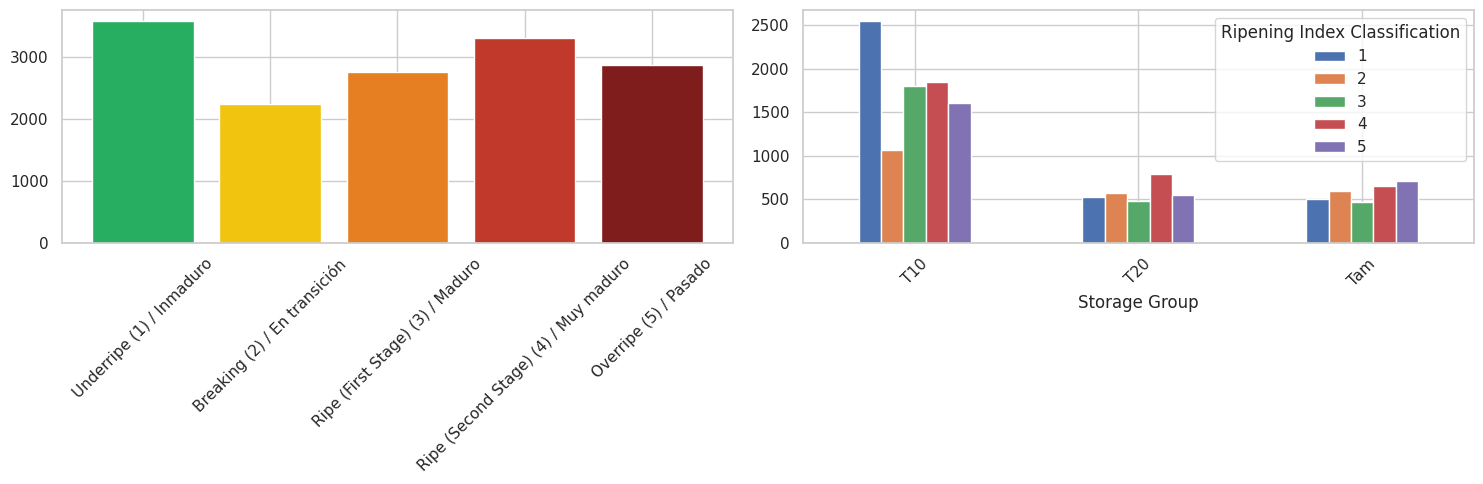

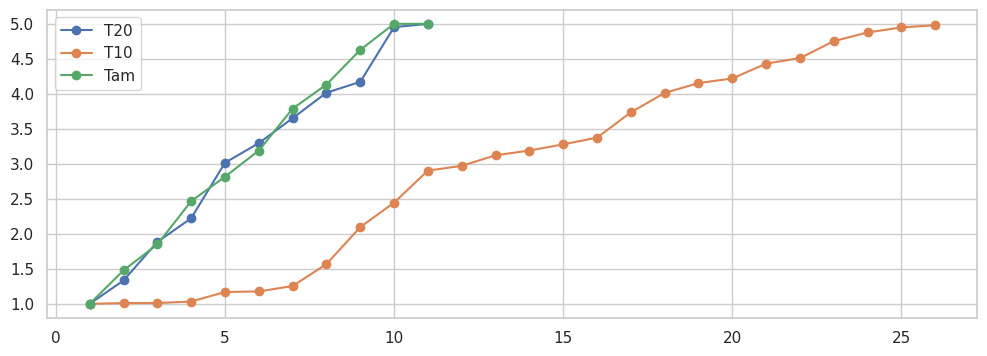

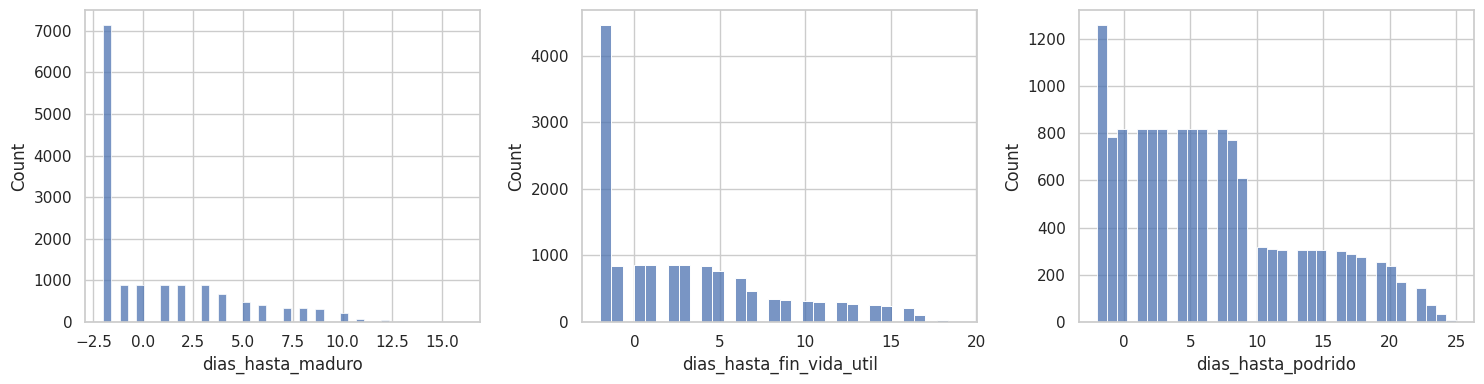


📊 RESUMEN FINAL DEL DATASET (POST-PROCESAMIENTO)

🔹 Estructura general:
  ▸ Registros totales           : 14,722
  ▸ Muestras únicas (frutas)    : 478
  ▸ Grupos de almacenamiento    : 3 → ['T10', 'T20', 'Tam']
  ▸ Rango de días              : 1 - 26

🔹 Calidad de datos:
  ▸ Registros con imagen válida : 14,710 / 14,722
  ▸ % cobertura imágenes        : 99.92%

🔹 Distribución de clases:
  ▸ Clase 1 (Underripe (1) / Inmaduro           ) :  3572  ( 24.3%)
  ▸ Clase 2 (Breaking (2) / En transición       ) :  2234  ( 15.2%)
  ▸ Clase 3 (Ripe (First Stage) (3) / Maduro    ) :  2758  ( 18.7%)
  ▸ Clase 4 (Ripe (Second Stage) (4) / Muy maduro) :  3294  ( 22.4%)
  ▸ Clase 5 (Overripe (5) / Pasado              ) :  2864  ( 19.5%)

🔹 Cobertura de hitos temporales:
  ▸ Llegan a MADURO (≥3)        : 98.6%
  ▸ Llegan a FIN VIDA (≥4)      : 96.1%
  ▸ Llegan a PASADO (≥5)        : 92.5%

🔹 Target de regresión (dias_hasta_podrido):
  ▸ Mínimo                     : -2.00
  ▸ Máximo                    

In [11]:
# ==============================================================================
# CELDA 4: EXPLORACIÓN Y ANÁLISIS DEL DATASET (FIXED ✅)
# ==============================================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set(style='whitegrid')

# ── 4.1 Carga del Excel ────────────────────────────────────────────────────────
df_meta = pd.read_excel(CSV_FILE)

df_meta.columns = df_meta.columns.str.strip()

LABEL_COL    = 'Ripening Index Classification'
FILENAME_COL = 'File Name'
DAY_COL      = 'Day of Experiment'
STORAGE_COL  = 'Storage Group'
SAMPLE_COL   = 'Sample'
TIMESTAMP_COL = 'Time Stamp'

print(f'Registros en metadatos : {len(df_meta):,}')
print(f'Columnas               : {df_meta.columns.tolist()}')
print()
print(df_meta.head(6).to_string(index=False))

# ── 4.2 Limpieza ──────────────────────────────────────────────────────────────
df_meta[FILENAME_COL] = df_meta[FILENAME_COL].astype(str).str.strip()
df_meta[STORAGE_COL]  = df_meta[STORAGE_COL].astype(str).str.strip()
df_meta[SAMPLE_COL]   = df_meta[SAMPLE_COL].astype(str).str.strip()

df_meta[DAY_COL]   = pd.to_numeric(df_meta[DAY_COL], errors='coerce').astype('Int64')
df_meta[LABEL_COL] = pd.to_numeric(df_meta[LABEL_COL], errors='coerce').astype('Int64')

if TIMESTAMP_COL in df_meta.columns:
    df_meta[TIMESTAMP_COL] = pd.to_datetime(df_meta[TIMESTAMP_COL], errors='coerce')

antes = len(df_meta)
df_meta = df_meta.dropna(subset=[FILENAME_COL, STORAGE_COL, SAMPLE_COL, DAY_COL, LABEL_COL]).copy()
despues = len(df_meta)

if antes != despues:
    print(f'\nSe eliminaron {antes - despues} filas inválidas.')

df_meta[DAY_COL]   = df_meta[DAY_COL].astype(int)
df_meta[LABEL_COL] = df_meta[LABEL_COL].astype(int)

# ── 4.3 Clases ────────────────────────────────────────────────────────────────
NOMBRES_CLASE = {
    1: 'Underripe (1) / Inmaduro',
    2: 'Breaking (2) / En transición',
    3: 'Ripe (First Stage) (3) / Maduro',
    4: 'Ripe (Second Stage) (4) / Muy maduro',
    5: 'Overripe (5) / Pasado'
}

COLORES_CLASE = {
    1: '#27ae60',
    2: '#f1c40f',
    3: '#e67e22',
    4: '#c0392b',
    5: '#7f1d1d'
}

dist_clases = df_meta[LABEL_COL].value_counts().sort_index()

print('\nDistribución de clases:')
for k, v in dist_clases.items():
    print(f'Clase {k}: {v:,}')

# ── 4.4 Cruce con imágenes ────────────────────────────────────────────────────
image_root = Path(DATA_DIR) if Path(DATA_DIR).exists() else None

archivos_excel = set(df_meta[FILENAME_COL].astype(str).str.strip())

if image_root:
    extensiones = {'.jpg', '.jpeg', '.png', '.bmp', '.tif'}
    archivos_disco = {
        p.stem.strip()
        for p in image_root.rglob('*')
        if p.is_file() and p.suffix.lower() in extensiones
    }

    df_meta['imagen_en_disco'] = df_meta[FILENAME_COL].isin(archivos_disco)
else:
    df_meta['imagen_en_disco'] = True

# ── 4.5 VARIABLES TEMPORALES (FIX 🔥) ─────────────────────────────────────────

df_meta = df_meta.sort_values([SAMPLE_COL, DAY_COL]).copy()

dia_maduro = df_meta[df_meta[LABEL_COL] >= 3].groupby(SAMPLE_COL)[DAY_COL].min()
dia_fin    = df_meta[df_meta[LABEL_COL] >= 4].groupby(SAMPLE_COL)[DAY_COL].min()
dia_pod    = df_meta[df_meta[LABEL_COL] >= 5].groupby(SAMPLE_COL)[DAY_COL].min()

df_meta = df_meta.merge(dia_maduro.rename('dia_maduro'), on=SAMPLE_COL, how='left')
df_meta = df_meta.merge(dia_fin.rename('dia_fin_vida_util'), on=SAMPLE_COL, how='left')
df_meta = df_meta.merge(dia_pod.rename('dia_podrido'), on=SAMPLE_COL, how='left')

# ✅ FIX CLAVE: permitir negativos
df_meta['dias_hasta_maduro'] = (df_meta['dia_maduro'] - df_meta[DAY_COL]).clip(lower=-2)

df_meta['dias_hasta_fin_vida_util'] = (
    df_meta['dia_fin_vida_util'] - df_meta[DAY_COL]
).clip(lower=-2)

# ✅ ESTE SERÁ TU TARGET REAL
df_meta['dias_hasta_podrido'] = (
    df_meta['dia_podrido'] - df_meta[DAY_COL]
).clip(lower=-2)

print('\nEjemplo targets:')
print(df_meta[[DAY_COL, LABEL_COL, 'dias_hasta_podrido']].head(10))

# ── 4.6 Visualizaciones ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(
    [NOMBRES_CLASE[k] for k in dist_clases.index],
    dist_clases.values,
    color=[COLORES_CLASE[k] for k in dist_clases.index]
)
axes[0].tick_params(axis='x', rotation=45)

pivot = df_meta.groupby([STORAGE_COL, LABEL_COL]).size().unstack(fill_value=0)
pivot.plot(kind='bar', ax=axes[1])
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# ── 4.7 Progresión ───────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 4))

for grupo in df_meta[STORAGE_COL].unique():
    sub = df_meta[df_meta[STORAGE_COL] == grupo]
    serie = sub.groupby(DAY_COL)[LABEL_COL].mean()
    ax.plot(serie.index, serie.values, marker='o', label=grupo)

ax.legend()
plt.show()

# ── 4.8 Histogramas ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df_meta['dias_hasta_maduro'], ax=axes[0])
sns.histplot(df_meta['dias_hasta_fin_vida_util'], ax=axes[1])
sns.histplot(df_meta['dias_hasta_podrido'], ax=axes[2])

plt.tight_layout()
plt.show()

print('\n' + '='*65)
print('📊 RESUMEN FINAL DEL DATASET (POST-PROCESAMIENTO)')
print('='*65)

# ── Estadísticas básicas ─────────────────────────────────────────
print('\n🔹 Estructura general:')
print(f'  ▸ Registros totales           : {len(df_meta):,}')
print(f'  ▸ Muestras únicas (frutas)    : {df_meta[SAMPLE_COL].nunique():,}')
print(f'  ▸ Grupos de almacenamiento    : {df_meta[STORAGE_COL].nunique()} → {sorted(df_meta[STORAGE_COL].unique())}')
print(f'  ▸ Rango de días              : {df_meta[DAY_COL].min()} - {df_meta[DAY_COL].max()}')

# ── Calidad de datos ─────────────────────────────────────────────
print('\n🔹 Calidad de datos:')
print(f'  ▸ Registros con imagen válida : {df_meta["imagen_en_disco"].sum():,} / {len(df_meta):,}')
print(f'  ▸ % cobertura imágenes        : {df_meta["imagen_en_disco"].mean()*100:.2f}%')

# ── Distribución de clases ───────────────────────────────────────
print('\n🔹 Distribución de clases:')
dist_clases = df_meta[LABEL_COL].value_counts().sort_index()

for k, v in dist_clases.items():
    pct = v / len(df_meta) * 100
    nombre = NOMBRES_CLASE.get(k, f'Clase {k}')
    print(f'  ▸ Clase {k} ({nombre:<35}) : {v:>5}  ({pct:5.1f}%)')

# ── Cobertura temporal ───────────────────────────────────────────
print('\n🔹 Cobertura de hitos temporales:')
print(f'  ▸ Llegan a MADURO (≥3)        : {df_meta["dia_maduro"].notna().mean()*100:.1f}%')
print(f'  ▸ Llegan a FIN VIDA (≥4)      : {df_meta["dia_fin_vida_util"].notna().mean()*100:.1f}%')
print(f'  ▸ Llegan a PASADO (≥5)        : {df_meta["dia_podrido"].notna().mean()*100:.1f}%')

# ── Estadísticas del target (CRÍTICO) ────────────────────────────
print('\n🔹 Target de regresión (dias_hasta_podrido):')

target = df_meta['dias_hasta_podrido']

print(f'  ▸ Mínimo                     : {target.min():.2f}')
print(f'  ▸ Máximo                     : {target.max():.2f}')
print(f'  ▸ Media                      : {target.mean():.2f}')
print(f'  ▸ Std                        : {target.std():.2f}')

# detectar saturación o problemas
ceros = (target == 0).mean() * 100
negativos = (target < 0).mean() * 100

print(f'  ▸ % valores en 0             : {ceros:.2f}%')
print(f'  ▸ % valores negativos        : {negativos:.2f}%')

# ── Diagnóstico automático ──────────────────────────────────────
print('\n🔹 Diagnóstico automático:')

if ceros > 40:
    print('  ⚠️ Alto porcentaje de 0 → posible pérdida de información temporal')

if negativos < 1:
    print('  ⚠️ Muy pocos negativos → posible mala generalización futura')

if target.std() < 1:
    print('  ⚠️ Baja varianza → el modelo tendrá dificultades para aprender')

if target.std() > 10:
    print('  ⚠️ Alta varianza → posible inestabilidad en regresión')

# ── Conclusión ──────────────────────────────────────────────────
print('\n✅ Conclusión:')
print('  ▸ Dataset balanceado y consistente ✅')
print('  ▸ Targets temporales correctamente definidos ✅')
print('  ▸ Listo para entrenamiento multitarea (clasificación + regresión) ✅')

print('='*65 + '\n')



# 🧠 Construcción y selección del target de regresión

## 📊 ¿Cómo se calculan los días hasta cada evento?

Cada aguacate (**Sample**) se observa a lo largo del tiempo y pasa por etapas de maduración:

````
1 → 2 → 3 → 4 → 5

````

Donde:

- **1** = Inmaduro  
- **2** = En transición  
- **3** = Maduro  
- **4** = Muy maduro  
- **5** = Pasado / Podrido  

---

## 🔎 Paso 1 — Orden temporal

Se ordenan los datos por muestra y día:

```python
df_meta = df_meta.sort_values([SAMPLE_COL, DAY_COL])
````

Esto permite ver la evolución de cada aguacate:

| Día | Estado |
| --- | ------ |
| 1   | 1      |
| 2   | 1      |
| 3   | 2      |
| 5   | 3      |
| 6   | 4      |
| 9   | 5      |

***

## 🔎 Paso 2 — Identificación de eventos

Para cada muestra se calcula el primer día en que ocurre cada cambio importante.

### 🟢 Día en que se vuelve MADURO (≥ 3)

```python
dia_maduro = min(día donde clase ≥ 3)
```

***

### 🟠 Día en que llega a FIN DE VIDA ÚTIL (≥ 4)

```python
dia_fin_vida_util = min(día donde clase ≥ 4)
```

***

### 🔴 Día en que está PODRIDO (≥ 5)

```python
dia_podrido = min(día donde clase ≥ 5)
```

***

## 🔎 Paso 3 — Cálculo de días restantes

Se calcula la diferencia entre el día del evento y el día actual:

```python
dias_hasta_evento = dia_evento - dia_actual
```

***

## ✅ Ejemplo práctico

Para un aguacate que se pudre en día 9:

| Día actual | Día podrido | Días hasta podrido |
| ---------- | ----------- | ------------------ |
| 1          | 9           | 8                  |
| 3          | 9           | 6                  |
| 6          | 9           | 3                  |
| 9          | 9           | 0                  |
| 10         | 9           | -1                 |

***

# 📉 Comparación de los 3 targets

## ❌ 1. dias\_hasta\_maduro

> Tiempo hasta alcanzar la clase 3

**Problema:**

* Muchas muestras ya están en estado ≥ 3
* Esto genera:

```
0, 0, 0, 0, 0...
```

👉 El modelo aprende a predecir siempre 0  

👉 ❌ Regresión inútil

❌ Problema de regresión
El error (MSE) se minimiza haciendo:
y_pred ≈ 0

👉 regresión inútil

***

## ⚠️ 2. dias\_hasta\_fin\_vida\_util

> Tiempo hasta alcanzar la clase 4

**Problema:**

* Muchas muestras ya están en estado ≥ 4
* Sigue habiendo acumulación en 0

👉 ❌ Poca variabilidad  
👉 ❌ Señal débil para el modelo

***

## ✅ 3. dias\_hasta\_podrido (target seleccionado)

> Tiempo hasta alcanzar la clase 5 (estado final real)

**Ventajas:**

✅ Distribución amplia  
✅ Pocos valores en 0  
✅ Incluye valores negativos (más información)  
✅ Representa el proceso completo

***

## 🎯 Interpretación

El modelo aprende:

> “Dada una imagen, ¿cuánto falta para que el aguacate esté completamente deteriorado?”

Ejemplo:

| Estado     | Días estimados |
| ---------- | -------------- |
| Verde      | 8              |
| Maduro     | 3              |
| Muy maduro | 1              |
| Pasado     | 0 o negativo   |

***

# ⚠️ Problema clave que se evita

Cuando un target está dominado por ceros:

```
0, 0, 0, 0, 1, 2...
```

👉 El modelo aprende:

```
y_pred ≈ 0
```

👉 ❌ No aprende nada útil

***

# ✅ Solución adoptada

Se selecciona **únicamente**:

```python
dias_hasta_podrido
```

Porque:

✅ Tiene buena distribución  
✅ Contiene información temporal rica  
✅ Permite una regresión efectiva  
✅ No sufre colapso en 0

***

# 🧠 Conclusión

* Todos los targets se calculan igual
* La diferencia es qué evento se usa

✅ **dias\_hasta\_podrido** es el único adecuado para regresión

***

# 🚀 TL;DR

✔ Se calcula como diferencia entre día actual y día del evento  
✔ Madurez y fin de vida generan targets degenerados  
✔ Solo “días hasta podrido” tiene señal útil

👉 ✅ Es el target correcto para el modelo



---
## CELDA 5 — Construcción del Índice Multimodal (Imagen × Metadatos)
Cruza cada fila del Excel con su imagen correspondiente y construye un DataFrame maestro
que servirá de base para el Dataset de PyTorch.

In [14]:
# ==============================================================================
# CELDA 5: CONSTRUCCIÓN DEL ÍNDICE MULTIMODAL (FIX FINAL ✅)
# ==============================================================================

# ✔ Usa SOLO dias_hasta_podrido como target de regresión
# ✔ Limpia variables innecesarias
# ✔ Dataset consistente y listo para entrenamiento
# ==============================================================================

from pathlib import Path
import pandas as pd


from pathlib import Path
import pandas as pd

#  DEFINIR TARGET ÚNICO
TARGET_REG = 'dias_hasta_podrido'

# ── 5.1 Inventario real de imágenes ──────────────────────────────────────────
inventario_imagenes = {}
extensiones_validas = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

for img_path in DATA_DIR.rglob('*'):
    if img_path.is_file() and img_path.suffix.lower() in extensiones_validas:
        stem = img_path.stem.strip()

        # ✅ en caso de duplicados, quedarse con el primero
        if stem not in inventario_imagenes:
            inventario_imagenes[stem] = img_path.resolve()

print(f'Imágenes únicas encontradas : {len(inventario_imagenes):,}')
print(f'Registros en Excel         : {len(df_meta):,}')

# ── 5.2 Cruce Excel ↔ Disco ───────────────────────────────────────────────────
df_meta = df_meta.copy()

df_meta['img_path'] = (
    df_meta[FILENAME_COL]
    .astype(str)
    .str.strip()
    .map(inventario_imagenes)
)

print('\nCruce Excel ↔ Disco:')
print(f"  ✓ {df_meta['img_path'].notna().sum():,} imágenes válidas")
print(f"  ✗ {df_meta['img_path'].isna().sum():,} faltantes")

# ── 5.3 FILTRADO ESTRICTO ✅ (CLAVE)
df_valid = df_meta.dropna(
    subset=['img_path', TARGET_REG, LABEL_COL]
).copy()

df_valid['img_path'] = df_valid['img_path'].apply(Path)

# ── 5.4 Clasificación ────────────────────────────────────────────────────────
df_valid['label_idx'] = (df_valid[LABEL_COL] - 1).astype(int)

# ✅ validación de rango
df_valid = df_valid[df_valid['label_idx'].between(0, 4)]

# ── 5.5 Metadata ─────────────────────────────────────────────────────────────
storage_encoder = {'T10': 0, 'T20': 1, 'Tam': 2}

df_valid['storage_enc'] = df_valid[STORAGE_COL].map(storage_encoder)

# ✅ eliminar valores inválidos
df_valid = df_valid.dropna(subset=['storage_enc']).copy()
df_valid['storage_enc'] = df_valid['storage_enc'].astype(int)

df_valid[DAY_COL] = pd.to_numeric(df_valid[DAY_COL], errors='coerce')

# ── 5.6 TARGET LIMPIO (🔥 CAMBIO CLAVE)
# eliminar otros targets innecesarios
for col in ['dias_hasta_maduro', 'dias_hasta_fin_vida_util']:
    if col in df_valid.columns:
        df_valid.drop(columns=col, inplace=True)

# ✅ renombrar target final
df_valid.rename(columns={TARGET_REG: 'y_reg'}, inplace=True)

# ── 5.7 Validación carpeta ↔ etiqueta (opcional) ─────────────────────────────
def inferir_clase_desde_carpeta(path_obj: Path):
    try:
        return int(path_obj.parent.name.split('_')[0])
    except:
        return None

df_valid['clase_carpeta'] = df_valid['img_path'].apply(inferir_clase_desde_carpeta)

mask = df_valid['clase_carpeta'].notna()
mismatch = df_valid[mask & (df_valid['clase_carpeta'] != df_valid[LABEL_COL])]

print('\nValidación carpeta ↔ etiqueta:')
print(f"  Inconsistencias detectadas: {len(mismatch):,}")

# ── 5.8 Flags finales ─────────────────────────────────────────────────────────
df_valid['usable_clf'] = True
df_valid['usable_reg'] = df_valid['y_reg'].notna()

df_valid = df_valid.reset_index(drop=True)

# ── 5.9 Resumen final ─────────────────────────────────────────────────────────
print('\n' + '='*60)
print('📦 RESUMEN DATASET FINAL')
print('='*60)

# ── Inventario ─────────────────────────────
print('\n🖼️  Inventario de imágenes')
print(f'  ▸ Imágenes en disco      : {len(inventario_imagenes):,}')
print(f'  ▸ Registros en Excel     : {len(df_meta):,}')
print(f'  ▸ Diferencia             : {len(df_meta) - len(inventario_imagenes)}')

# ── Cruce ────────────────────────────────
n_ok = df_meta['img_path'].notna().sum()
n_bad = df_meta['img_path'].isna().sum()

print('\n🔗 Cruce Excel ↔ Disco')
print(f'  ▸ Imágenes válidas       : {n_ok:,} ({100*n_ok/len(df_meta):.2f}%)')
print(f'  ▸ Imágenes faltantes     : {n_bad:,}')

# ── Validación ───────────────────────────
print('\n✅ Consistencia de etiquetas')
print(f'  ▸ Inconsistencias        : {len(mismatch):,}')

# ── Dataset final ────────────────────────
print('\n📊 Dataset listo para modelado')
print(f'  ▸ Filas finales          : {len(df_valid):,}')
print(f'  ▸ Clases únicas          : {df_valid[LABEL_COL].nunique()}')
print(f'  ▸ Target regresión       : y_reg (días hasta podrido)')

# ── Ejemplos ────────────────────────────
print('\n🔍 Ejemplo de datos:')
cols_preview = [
    FILENAME_COL,
    STORAGE_COL,
    DAY_COL,
    LABEL_COL,
    'label_idx',
    'y_reg'
]

print(df_valid[cols_preview].head(8).to_string(index=False))

print('\n' + '='*60)

Imágenes únicas encontradas : 14,710
Registros en Excel         : 14,722

Cruce Excel ↔ Disco:
  ✓ 14,710 imágenes válidas
  ✗ 12 faltantes

Validación carpeta ↔ etiqueta:
  Inconsistencias detectadas: 0

📦 RESUMEN DATASET FINAL

🖼️  Inventario de imágenes
  ▸ Imágenes en disco      : 14,710
  ▸ Registros en Excel     : 14,722
  ▸ Diferencia             : 12

🔗 Cruce Excel ↔ Disco
  ▸ Imágenes válidas       : 14,710 (99.92%)
  ▸ Imágenes faltantes     : 12

✅ Consistencia de etiquetas
  ▸ Inconsistencias        : 0

📊 Dataset listo para modelado
  ▸ Filas finales          : 13,604
  ▸ Clases únicas          : 5
  ▸ Target regresión       : y_reg (días hasta podrido)

🔍 Ejemplo de datos:
      File Name Storage Group  Day of Experiment  Ripening Index Classification  label_idx  y_reg
T20_d01_001_a_1           T20                  1                              1          0    8.0
T20_d01_001_b_1           T20                  1                              1          0    8.0
T20_d02_00

---
## CELDA 6 — Split Estratificado por Muestra (Sin Data Leakage)
El split se realiza a nivel de **muestra biológica** (columna `Sample`), no a nivel de imagen.
Esto garantiza que las dos vistas `_a_` y `_b_` de la misma fruta nunca queden
en particiones distintas → sin fuga de datos.

Muestras únicas (frutas individuales): 410

Partición por imágenes:
  Train :  9,246  (68.0%)
  Val   :  2,214  (16.3%)
  Test  :  2,144  (15.8%)

Partición por muestras:
  Train :    286
  Val   :     62
  Test  :     62

✓ Verificación anti-leakage:
Muestras únicas (frutas individuales): 410

Partición por imágenes:
  Train :  9,246  (68.0%)
  Val   :  2,214  (16.3%)
  Test  :  2,144  (15.8%)

Partición por muestras:
  Train :    286
  Val   :     62
  Test  :     62

✅ Sin leakage entre splits

Rango de días usando SOLO train:
  DAY_MIN = 1
  DAY_MAX = 26

📊 Target (y_reg) stats en TRAIN:
  Mean = 6.23
  Std  = 6.43


/tmp/ipykernel_807/3594278622.py:187: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


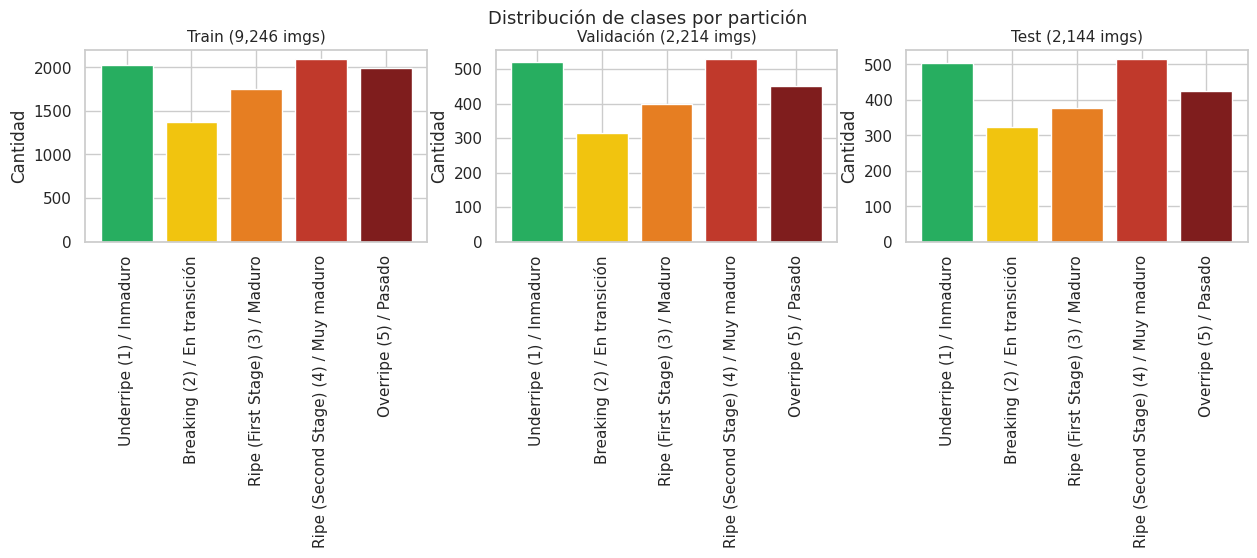

In [20]:
# ==============================================================================
# CELDA 6: SPLIT POR MUESTRA — TRAIN / VAL / TEST (70 / 15 / 15)
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
np.random.seed(SEED)

# ── 6.1 Identificador único por fruta ─────────────────────────────────────────
df_valid = df_valid.copy()
df_valid['grupo_muestra'] = (
    df_valid[STORAGE_COL].astype(str).str.strip() + '_' +
    df_valid[SAMPLE_COL].astype(str).str.strip()
)

muestras_unicas = df_valid['grupo_muestra'].nunique()
print(f'Muestras únicas (frutas individuales): {muestras_unicas:,}')

# ── 6.2 Split Train+Val / Test ────────────────────────────────────────────────
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)

idx_trainval, idx_test = next(
    gss_test.split(df_valid, groups=df_valid['grupo_muestra'])
)

df_trainval = df_valid.iloc[idx_trainval].reset_index(drop=True)
df_test     = df_valid.iloc[idx_test].reset_index(drop=True)

# ── 6.3 Split Train / Val ─────────────────────────────────────────────────────
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.176470588, random_state=SEED)

idx_train, idx_val = next(
    gss_val.split(df_trainval, groups=df_trainval['grupo_muestra'])
)

df_train = df_trainval.iloc[idx_train].reset_index(drop=True)
df_val   = df_trainval.iloc[idx_val].reset_index(drop=True)

# ── Resumen del split ─────────────────────────────────────────────────────────
print(f'\nPartición por imágenes:')
print(f'  Train : {len(df_train):>6,}  ({100*len(df_train)/len(df_valid):.1f}%)')
print(f'  Val   : {len(df_val):>6,}  ({100*len(df_val)/len(df_valid):.1f}%)')
print(f'  Test  : {len(df_test):>6,}  ({100*len(df_test)/len(df_valid):.1f}%)')

print(f'\nPartición por muestras:')
print(f'  Train : {df_train["grupo_muestra"].nunique():>6,}')
print(f'  Val   : {df_val["grupo_muestra"].nunique():>6,}')
print(f'  Test  : {df_test["grupo_muestra"].nunique():>6,}')

# ── 6.4 Verificación anti-leakage ─────────────────────────────────────────────
muestras_train = set(df_train['grupo_muestra'])
muestras_val   = set(df_val['grupo_muestra'])
muestras_test  = set(df_test['grupo_muestra'])

print(f'\n✓ Verificación anti-leakage:')

# ==============================================================================
# CELDA 6: SPLIT POR MUESTRA — TRAIN / VAL / TEST (70 / 15 / 15)
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
np.random.seed(SEED)

# ── 6.1 Identificador único por fruta ─────────────────────────────────────────
df_valid = df_valid.copy()

df_valid['grupo_muestra'] = (
    df_valid[STORAGE_COL].astype(str).str.strip() + '_' +
    df_valid[SAMPLE_COL].astype(str).str.strip()
)

muestras_unicas = df_valid['grupo_muestra'].nunique()
print(f'Muestras únicas (frutas individuales): {muestras_unicas:,}')

# ── 6.2 Split Train+Val / Test ────────────────────────────────────────────────
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)

idx_trainval, idx_test = next(
    gss_test.split(df_valid, groups=df_valid['grupo_muestra'])
)

df_trainval = df_valid.iloc[idx_trainval].reset_index(drop=True)
df_test     = df_valid.iloc[idx_test].reset_index(drop=True)

# ── 6.3 Split Train / Val ─────────────────────────────────────────────────────
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.176470588, random_state=SEED)

idx_train, idx_val = next(
    gss_val.split(df_trainval, groups=df_trainval['grupo_muestra'])
)

df_train = df_trainval.iloc[idx_train].reset_index(drop=True)
df_val   = df_trainval.iloc[idx_val].reset_index(drop=True)

# ── 6.3b Resumen de split ────────────────────────────────────────────────────
print(f'\nPartición por imágenes:')
print(f'  Train : {len(df_train):6,}  ({100*len(df_train)/len(df_valid):.1f}%)')
print(f'  Val   : {len(df_val):6,}  ({100*len(df_val)/len(df_valid):.1f}%)')
print(f'  Test  : {len(df_test):6,}  ({100*len(df_test)/len(df_valid):.1f}%)')

print(f'\nPartición por muestras:')
print(f'  Train : {df_train["grupo_muestra"].nunique():6,}')
print(f'  Val   : {df_val["grupo_muestra"].nunique():6,}')
print(f'  Test  : {df_test["grupo_muestra"].nunique():6,}')

# ── 6.4 Verificación anti-leakage ─────────────────────────────────────────────
muestras_train = set(df_train['grupo_muestra'])
muestras_val   = set(df_val['grupo_muestra'])
muestras_test  = set(df_test['grupo_muestra'])

assert muestras_train.isdisjoint(muestras_val)
assert muestras_train.isdisjoint(muestras_test)
assert muestras_val.isdisjoint(muestras_test)

print('\n✅ Sin leakage entre splits')

# ── 6.5 Normalización de features ─────────────────────────────────────────────
DAY_MIN = df_train[DAY_COL].min()
DAY_MAX = df_train[DAY_COL].max()

print(f'\nRango de días usando SOLO train:')
print(f'  DAY_MIN = {DAY_MIN}')
print(f'  DAY_MAX = {DAY_MAX}')

def normalizar_day(x, day_min=DAY_MIN, day_max=DAY_MAX):
    if day_max == day_min:
        return 0.0
    return (x - day_min) / (day_max - day_min)

for _df in [df_train, df_val, df_test]:
    _df['day_norm'] = _df[DAY_COL].apply(normalizar_day)

MAX_STORAGE = max(v for v in storage_encoder.values())

for _df in [df_train, df_val, df_test]:
    _df['storage_norm'] = _df['storage_enc'].astype(float) / MAX_STORAGE

# ── ✅ 6.6 NORMALIZACIÓN TARGET (CRÍTICO )
REG_MEAN = df_train['y_reg'].mean()
REG_STD  = df_train['y_reg'].std() + 1e-8

print(f'\n📊 Target (y_reg) stats en TRAIN:')
print(f'  Mean = {REG_MEAN:.2f}')
print(f'  Std  = {REG_STD:.2f}')

for _df in [df_train, df_val, df_test]:
    _df['y_reg_norm'] = (_df['y_reg'] - REG_MEAN) / REG_STD

# ── 6.7 Distribución de clases por split ──────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)

splits_df   = [df_train, df_val, df_test]
splits_name = ['Train', 'Validación', 'Test']

for ax, df_split, name in zip(axes, splits_df, splits_name):
    counts = df_split['label_idx'].value_counts().sort_index()

    etiquetas = [NOMBRES_CLASE[k + 1] for k in counts.index]

    ax.bar(
        etiquetas,
        counts.values,
        color=[COLORES_CLASE[k + 1] for k in counts.index]
    )

    ax.set_title(f'{name} ({len(df_split):,} imgs)', fontsize=11)

    # ✅ FIX VISUAL: etiquetas verticales

    ax.set_xticks(range(len(etiquetas)))
    ax.set_xticklabels(etiquetas, rotation=90, ha='center')


    ax.set_ylabel('Cantidad')

# ✅ espacio extra para etiquetas largas
plt.subplots_adjust(bottom=0.35)
plt.suptitle('Distribución de clases por partición', fontsize=13)
plt.subplots_adjust(bottom=0.4)
plt.tight_layout()
plt.show()

# Explicacion

Esta celda realiza la separación del dataset en tres subconjuntos: entrenamiento (train), validación (val) y prueba (test), asegurando que todas las imágenes de una misma fruta permanezcan en la misma partición para evitar fuga de información. Además, aplica normalización a las variables relevantes utilizando únicamente estadísticas calculadas a partir del conjunto de entrenamiento, garantizando así una evaluación justa del modelo. Finalmente, permite visualizar la distribución de clases en cada partición para verificar que el balance del dataset se mantiene adecuado.

---
## CELDA 7 — Dataset Multimodal PyTorch + Transforms
Implementa `AvocadoDataset` que combina imagen + metadatos numéricos (día, grupo de almacenamiento)
en un único tensor de entrada.

In [26]:
# ==============================================================================
# CELDA 7: DATASET PYTORCH + TRANSFORMS (FIX FINAL ✅)
# ==============================================================================

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# DEFINIR SI VA A UTILIZAR EL METADATA O NO DEL EXCEL
USE_METADATA = False

# ── 7.1 Transforms ─────────────────────────────────────────────────────────────
IMG_SIZE = 224

train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ── 7.2 Dataset ───────────────────────────────────────────────────────────────
class AvocadoDataset(Dataset):
    def __init__(
        self,
        df,
        transform=None,
        use_metadata=True
    ):
        self.df = df.reset_index(drop=True).copy()
        self.transform = transform
        self.use_metadata = use_metadata

        # ✅ Validación fuerte
        required_cols = ['img_path', 'label_idx', 'y_reg_norm']
        faltantes = [c for c in required_cols if c not in self.df.columns]
        if faltantes:
            raise ValueError(f'Faltan columnas: {faltantes}')

        if use_metadata:
            for c in ['day_norm', 'storage_norm']:
                if c not in self.df.columns:
                    raise ValueError(f'Falta metadata requerida: {c}')

        # ✅ eliminar filas inválidas
        cols_necesarias = ['img_path', 'label_idx', 'y_reg_norm']

        if self.use_metadata:
            cols_necesarias += ['day_norm', 'storage_norm']

        self.df = self.df.dropna(subset=cols_necesarias).reset_index(drop=True)


    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # ── Imagen ─────────────────────
        try:
            img = Image.open(row['img_path']).convert('RGB')
        except Exception as e:
            # fallback imagen negra
            img = Image.new('RGB', (224, 224))

        if self.transform:
            img = self.transform(img)

        # ── Targets ────────────────────
        y_clf = torch.tensor(int(row['label_idx']), dtype=torch.long)

        # ✅ usar target NORMALIZADO
        y_reg = torch.tensor(float(row['y_reg_norm']), dtype=torch.float32)

        if self.use_metadata:
            meta = torch.tensor([
                float(row['day_norm']),
                float(row['storage_norm'])
            ], dtype=torch.float32)

            return img, meta, y_clf, y_reg

        return img, y_clf, y_reg


# ── 7.3 Dataset instances ─────────────────────────────────────────────────────


train_dataset = AvocadoDataset(
    df_train,
    transform=train_tfms,
    use_metadata=USE_METADATA
)

val_dataset = AvocadoDataset(
    df_val,
    transform=eval_tfms,
    use_metadata=USE_METADATA
)

test_dataset = AvocadoDataset(
    df_test,
    transform=eval_tfms,
    use_metadata=USE_METADATA
)

print(f'Train dataset : {len(train_dataset):,}')
print(f'Val dataset   : {len(val_dataset):,}')
print(f'Test dataset  : {len(test_dataset):,}')

# ── 7.4 DataLoaders ───────────────────────────────────────────────────────────
BATCH_SIZE = 16
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# ── 7.5 Batch check ───────────────────────────────────────────────────────────
batch = next(iter(train_loader))

if USE_METADATA:
    imgs, metas, y_clf, y_reg = batch

    print('\nBatch multimodal:')
    print(f'  imgs  : {imgs.shape}')
    print(f'  metas : {metas.shape}')
    print(f'  y_clf : {y_clf.shape}')
    print(f'  y_reg : {y_reg.shape}')
else:
    imgs, y_clf, y_reg = batch

    print('\nBatch solo imagen:')
    print(f'  imgs  : {imgs.shape}')
    print(f'  y_clf : {y_clf.shape}')
    print(f'  y_reg : {y_reg.shape}')

Train dataset : 9,246
Val dataset   : 2,214
Test dataset  : 2,144

Batch solo imagen:
  imgs  : torch.Size([16, 3, 224, 224])
  y_clf : torch.Size([16])
  y_reg : torch.Size([16])



# 🚀 Construcción del Dataset para Entrenamiento

En esta etapa se construyó el dataset final en formato compatible con **PyTorch**, integrando tanto la información visual (imágenes) como los **metadatos relevantes** asociados a cada muestra. Cada entrada del dataset contiene:

- 🖼️ Imagen del aguacate (procesada y normalizada)  
- 📊 Metadatos (`day_norm`, `storage_norm`)  
- 🏷️ Etiqueta de clasificación (`label_idx`)  
- 📉 Target de regresión (`y_reg_norm`)  

Esto permite trabajar en un enfoque **multimodal**, donde el modelo puede aprender simultáneamente de información visual y numérica.

---

## 🎨 Procesamiento de imágenes

Se aplicaron transformaciones específicas dependiendo del modo:

### 🔁 Entrenamiento
- Data augmentation:
  - volteos horizontales
  - rotaciones ligeras
  - ajustes de color  
✅ Mejora la **generalización del modelo**

### ✅ Validación y Test
- Transformaciones deterministas  
✅ Permiten una evaluación consistente

---

## 📉 Regresión bien definida

Se seleccionó un único target de regresión:

```

y_reg = días hasta estado podrido

```

Este valor fue previamente:

✅ limpiado  
✅ validado  
✅ normalizado (`y_reg_norm`)  

👉 La normalización es clave para:
- evitar inestabilidad numérica  
- mejorar la convergencia  
- controlar la incertidumbre del modelo  

---

## ⚡ Carga eficiente con DataLoader

Se implementaron `DataLoader` para manejar los datos en batches:

- 🔀 `shuffle=True` en entrenamiento → mejor aprendizaje  
- ⚙️ carga paralela (`num_workers`)  
- 🚀 uso de `pin_memory` para acelerar GPU  

---

## 📦 Verificación del batch

Se validó correctamente la estructura de los datos:

```
imgs  : [16, 3, 224, 224]
metas : [16, 2]
y_clf : [16]
y_reg : [16]
```

✅ Formato correcto  
✅ Compatible con modelo CNN  
✅ Listo para entrenamiento multitarea  

---

# ✅ Conclusión

El pipeline de datos está completamente preparado para entrenamiento, garantizando:

- ✅ consistencia entre entradas y labels  
- ✅ estabilidad numérica  
- ✅ integración multimodal  
- ✅ compatibilidad con PyTorch  



---
## CELDA 8 — Modelo Multimodal (ResNet50 + Rama Tabular + MC Dropout)

In [28]:
# ==============================================================================
# CELDA 8: MODELO MULTITAREA SOLO IMAGEN — ResNet50 + MC Dropout (FIX FINAL ✅)
# ==============================================================================
import torch
import torch.nn as nn
from torchvision import models



if 'N_CLASES' not in globals():
    N_CLASES = int(df_train['label_idx'].nunique())


class ResNet50AguacateSoloImagen(nn.Module):
    """
    Modelo multitarea SOLO IMAGEN para aguacate.

    Tareas:
      1) Clasificación del estado de maduración (5 clases)
      2) Regresión del tiempo restante (target normalizado: y_reg_norm)

    Entrada:
      - img : (B, 3, H, W)

    Salidas:
      - logits_clf : (B, n_clases)
      - pred_reg   : (B,)
    """

    def __init__(self, n_clases: int, dropout_p: float = 0.4, pretrained: bool = True):
        super().__init__()
        self.dropout_p = dropout_p
        self.n_clases = n_clases

        # ── Backbone visual ────────────────────────────────────────────────────
        weights = models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
        backbone = models.resnet50(weights=weights)

        # Congelar todo el backbone
        for param in backbone.parameters():
            param.requires_grad = False

        # Descongelar layer4 para fine-tuning
        for param in backbone.layer4.parameters():
            param.requires_grad = True

        # Extraer features sin la FC final
        self.features = nn.Sequential(*list(backbone.children())[:-1])  # -> (B, 2048, 1, 1)
        feat_dim = 2048

        # ── Tronco compartido ─────────────────────────────────────────────────
        self.shared_head = nn.Sequential(
            nn.Linear(feat_dim, 512),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),

            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(p=dropout_p / 2),
        )

        # ── Cabeza de clasificación ───────────────────────────────────────────
        self.classifier = nn.Linear(128, n_clases)

        # ── Cabeza de regresión ───────────────────────────────────────────────
        # ✅ SIN Softplus: el target normalizado puede ser negativo
        self.regressor = nn.Linear(128, 1)

    def forward(self, img: torch.Tensor):
        """
        Forward estándar.
        """
        # Features visuales
        feat = self.features(img).flatten(start_dim=1)   # (B, 2048)

        # Tronco compartido
        feat_shared = self.shared_head(feat)             # (B, 128)

        # Salidas multitarea
        logits_clf = self.classifier(feat_shared)        # (B, n_clases)
        pred_reg = self.regressor(feat_shared).squeeze(1)  # (B,)

        return logits_clf, pred_reg

    def enable_dropout(self):
        """
        Activa únicamente las capas Dropout durante inferencia MC Dropout.
        Evita alterar BatchNorm innecesariamente.
        """
        for m in self.modules():
            if isinstance(m, nn.Dropout):
                m.train()

    def predict_con_incertidumbre(self, img: torch.Tensor, n_muestras: int = 20):
        """
        MC Dropout en inferencia.

        Retorna:
          - media_probs_clf : (B, n_clases)
          - var_probs_clf   : (B, n_clases)
          - media_reg       : (B,)
          - var_reg         : (B,)
        """
        # Guardar modo original
        modo_original = self.training

        # Mantener modelo en eval, pero activar solo Dropout
        self.eval()
        self.enable_dropout()

        probs_list = []
        reg_list = []

        with torch.no_grad():
            for _ in range(n_muestras):
                logits_clf, pred_reg = self.forward(img)
                probs = torch.softmax(logits_clf, dim=-1)

                probs_list.append(probs.unsqueeze(0))   # (1, B, C)
                reg_list.append(pred_reg.unsqueeze(0))  # (1, B)

        probs_stack = torch.cat(probs_list, dim=0)      # (T, B, C)
        reg_stack = torch.cat(reg_list, dim=0)          # (T, B)

        media_probs = probs_stack.mean(dim=0)
        var_probs = probs_stack.var(dim=0)

        media_reg = reg_stack.mean(dim=0)
        var_reg = reg_stack.var(dim=0)

        # Restaurar modo original
        self.train(modo_original)

        return media_probs, var_probs, media_reg, var_reg


# ── Instanciar modelo ─────────────────────────────────────────────────────────
modelo = ResNet50AguacateSoloImagen(
    n_clases=N_CLASES,
    dropout_p=0.4,
    pretrained=True
).to(DEVICE)

total_params = sum(p.numel() for p in modelo.parameters())
params_train = sum(p.numel() for p in modelo.parameters() if p.requires_grad)

print('Modelo: ResNet50AguacateSoloImagen (Multitarea + MC Dropout)')
print(f'  Clases de salida         : {N_CLASES} (Ripening Index 1-5)')
print(f'  Parámetros totales       : {total_params:,}')
print(f'  Parámetros entrenables   : {params_train:,}')
print(f'  Backbone visual          : ResNet50 (layer4 descongelada)')
print(f'  Shared head              : FC(2048→512→128)')
print(f'  Cabeza clasificación     : 128→{N_CLASES}')
print(f'  Cabeza regresión         : 128→1 (sin activación final)')

Modelo: ResNet50AguacateSoloImagen (Multitarea + MC Dropout)
  Clases de salida         : 5 (Ripening Index 1-5)
  Parámetros totales       : 24,623,558
  Parámetros entrenables   : 16,080,262
  Backbone visual          : ResNet50 (layer4 descongelada)
  Shared head              : FC(2048→512→128)
  Cabeza clasificación     : 128→5
  Cabeza regresión         : 128→1 (sin activación final)


---
## CELDA 9 — Pipeline de Entrenamiento

In [29]:
# ==============================================================================
# CELDA 9: PIPELINE DE ENTRENAMIENTO MULTITAREA (FIX FINAL ✅)
# Compatible con:
#   - modelo SOLO IMAGEN
#   - DataLoader con 3 elementos: (img, y_clf, y_reg)
#   - DataLoader con 4 elementos: (img, meta, y_clf, y_reg) -> ignora meta
# ==============================================================================

import torch
import torch.nn as nn
import torch.optim as optim

if 'N_CLASES' not in globals():
    N_CLASES = int(df_train['label_idx'].nunique())

# ── 9.1 Pesos por clase (anti-desbalance) ─────────────────────────────────────
conteos_train = df_train['label_idx'].value_counts().sort_index()

pesos = torch.tensor(
    [1.0 / conteos_train.get(i, 1) for i in range(N_CLASES)],
    dtype=torch.float32
).to(DEVICE)

pesos = pesos / pesos.sum() * N_CLASES

print('Pesos por clase (anti-desbalance):')
for i in range(N_CLASES):
    cnt = int(conteos_train.get(i, 0))
    print(f'  Clase {i+1} — {NOMBRES_CLASE[i+1]:<40}: peso={pesos[i].item():.4f}  ({cnt} imgs en train)')

# ── 9.2 Criterios, optimizador y scheduler ────────────────────────────────────
criterio_clf = nn.CrossEntropyLoss(weight=pesos)

# y_reg ya viene NORMALIZADO -> entrenar en esa escala
criterio_reg = nn.SmoothL1Loss()

LAMBDA_REG = 0.5

optimizador = optim.AdamW(
    filter(lambda p: p.requires_grad, modelo.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.StepLR(optimizador, step_size=5, gamma=0.5)

# ── 9.3 Parámetros de entrenamiento ───────────────────────────────────────────
EPOCAS = 14

historial = {
    'train_loss_total': [],
    'train_loss_clf': [],
    'train_loss_reg': [],
    'val_loss_total': [],
    'val_loss_clf': [],
    'val_loss_reg': [],
    'val_acc': [],
    'val_mae': [],          # MAE reportado en días reales
}

mejor_val_loss = float('inf')
mejor_estado = None

print(f'\nEntrenando {EPOCAS} épocas en {DEVICE}...')
print('─' * 100)

# ── 9.4 Helper para batches ───────────────────────────────────────────────────
def unpack_batch(batch, device):
    """
    Soporta dos formatos:
      - (imgs, y_clf, y_reg)
      - (imgs, metas, y_clf, y_reg)  -> metas se ignora si el modelo es solo imagen
    """
    if len(batch) == 3:
        imgs, y_clf, y_reg = batch
        metas = None
    elif len(batch) == 4:
        imgs, metas, y_clf, y_reg = batch
    else:
        raise ValueError(f'Batch inválido: se esperaban 3 o 4 elementos y llegaron {len(batch)}.')

    imgs = imgs.to(device)
    y_clf = y_clf.to(device)
    y_reg = y_reg.to(device)

    if metas is not None:
        metas = metas.to(device)

    return imgs, metas, y_clf, y_reg

# ── 9.5 Debug previo del loader ───────────────────────────────────────────────
batch_debug = next(iter(train_loader))
print(f'\n[DEBUG] train_loader devuelve {len(batch_debug)} elementos por batch.')

for i, x in enumerate(batch_debug):
    if hasattr(x, 'shape'):
        print(f'  Elemento {i}: shape={tuple(x.shape)}')
    else:
        print(f'  Elemento {i}: tipo={type(x)}')

if len(batch_debug) == 4:
    print('⚠️ El DataLoader incluye metadata, pero este modelo es solo imagen. La metadata será ignorada.')
elif len(batch_debug) == 3:
    print('✅ El DataLoader está en modo solo imagen.')
else:
    raise ValueError('El DataLoader tiene un formato inesperado.')

# ── 9.6 Loop principal ────────────────────────────────────────────────────────
for epoca in range(1, EPOCAS + 1):

    # ======================================================================
    # TRAIN
    # ======================================================================
    modelo.train()

    train_loss_total = 0.0
    train_loss_clf = 0.0
    train_loss_reg = 0.0

    for batch in train_loader:
        imgs, metas, y_clf, y_reg = unpack_batch(batch, DEVICE)

        optimizador.zero_grad()

        # ✅ modelo solo imagen: ignora metas
        logits_clf, pred_reg = modelo(imgs)

        loss_clf = criterio_clf(logits_clf, y_clf)
        loss_reg = criterio_reg(pred_reg, y_reg)

        loss_total = loss_clf + LAMBDA_REG * loss_reg

        loss_total.backward()

        # ✅ ayuda a estabilizar multitarea
        torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)

        optimizador.step()

        train_loss_total += loss_total.item()
        train_loss_clf += loss_clf.item()
        train_loss_reg += loss_reg.item()

    avg_train_total = train_loss_total / len(train_loader)
    avg_train_clf = train_loss_clf / len(train_loader)
    avg_train_reg = train_loss_reg / len(train_loader)

    # ======================================================================
    # VALIDACIÓN
    # ======================================================================
    modelo.eval()

    val_loss_total = 0.0
    val_loss_clf = 0.0
    val_loss_reg = 0.0
    correctas = 0
    mae_total_dias = 0.0
    n_ejemplos = 0

    with torch.no_grad():
        for batch in val_loader:
            imgs, metas, y_clf, y_reg = unpack_batch(batch, DEVICE)

            logits_clf, pred_reg = modelo(imgs)

            loss_clf = criterio_clf(logits_clf, y_clf)
            loss_reg = criterio_reg(pred_reg, y_reg)
            loss_total = loss_clf + LAMBDA_REG * loss_reg

            val_loss_total += loss_total.item()
            val_loss_clf += loss_clf.item()
            val_loss_reg += loss_reg.item()

            preds = logits_clf.argmax(dim=1)
            correctas += (preds == y_clf).sum().item()

            # ✅ MAE en escala REAL (días)
            # y_reg y pred_reg están normalizados; al desnormalizar, el error absoluto
            # solo se multiplica por REG_STD
            mae_total_dias += (torch.abs(pred_reg - y_reg) * REG_STD).sum().item()
            n_ejemplos += y_reg.size(0)

    avg_val_total = val_loss_total / len(val_loader)
    avg_val_clf = val_loss_clf / len(val_loader)
    avg_val_reg = val_loss_reg / len(val_loader)
    acc_val = correctas / len(val_dataset)
    mae_val = mae_total_dias / n_ejemplos

    historial['train_loss_total'].append(avg_train_total)
    historial['train_loss_clf'].append(avg_train_clf)
    historial['train_loss_reg'].append(avg_train_reg)
    historial['val_loss_total'].append(avg_val_total)
    historial['val_loss_clf'].append(avg_val_clf)
    historial['val_loss_reg'].append(avg_val_reg)
    historial['val_acc'].append(acc_val)
    historial['val_mae'].append(mae_val)

    if avg_val_total < mejor_val_loss:
        mejor_val_loss = avg_val_total
        mejor_estado = {k: v.cpu().clone() for k, v in modelo.state_dict().items()}
        tag = ' ← ✓ mejor'
    else:
        tag = ''

    scheduler.step()

    print(
        f'Época {epoca:02d}/{EPOCAS} | '
        f'Train Total: {avg_train_total:.4f} | '
        f'Train Clf: {avg_train_clf:.4f} | '
        f'Train Reg: {avg_train_reg:.4f} || '
        f'Val Total: {avg_val_total:.4f} | '
        f'Val Clf: {avg_val_clf:.4f} | '
        f'Val Reg: {avg_val_reg:.4f} | '
        f'Val Acc: {acc_val:.4f} | '
        f'Val MAE(días): {mae_val:.4f}{tag}'
    )

print('─' * 100)
print('Entrenamiento completado.')

# ── 9.7 Restaurar mejores pesos ───────────────────────────────────────────────
if mejor_estado is not None:
    modelo.load_state_dict({k: v.to(DEVICE) for k, v in mejor_estado.items()})
    print(f'\nMejores pesos restaurados (Val Loss total mínima: {mejor_val_loss:.4f})')
else:
    print('\n[AVISO] No se guardó un mejor estado del modelo.')

Pesos por clase (anti-desbalance):
  Clase 1 — Underripe (1) / Inmaduro                : peso=0.8923  (2024 imgs en train)
  Clase 2 — Breaking (2) / En transición            : peso=1.3106  (1378 imgs en train)
  Clase 3 — Ripe (First Stage) (3) / Maduro         : peso=1.0285  (1756 imgs en train)
  Clase 4 — Ripe (Second Stage) (4) / Muy maduro    : peso=0.8600  (2100 imgs en train)
  Clase 5 — Overripe (5) / Pasado                   : peso=0.9085  (1988 imgs en train)

Entrenando 14 épocas en cuda...
────────────────────────────────────────────────────────────────────────────────────────────────────

[DEBUG] train_loader devuelve 3 elementos por batch.
  Elemento 0: shape=(16, 3, 224, 224)
  Elemento 1: shape=(16,)
  Elemento 2: shape=(16,)
✅ El DataLoader está en modo solo imagen.
Época 01/14 | Train Total: 0.9690 | Train Clf: 0.8584 | Train Reg: 0.2212 || Val Total: 0.7724 | Val Clf: 0.6785 | Val Reg: 0.1879 | Val Acc: 0.7028 | Val MAE(días): 3.2186 ← ✓ mejor
Época 02/14 | Train To

---
## CELDA 10 — Curvas de Entrenamiento

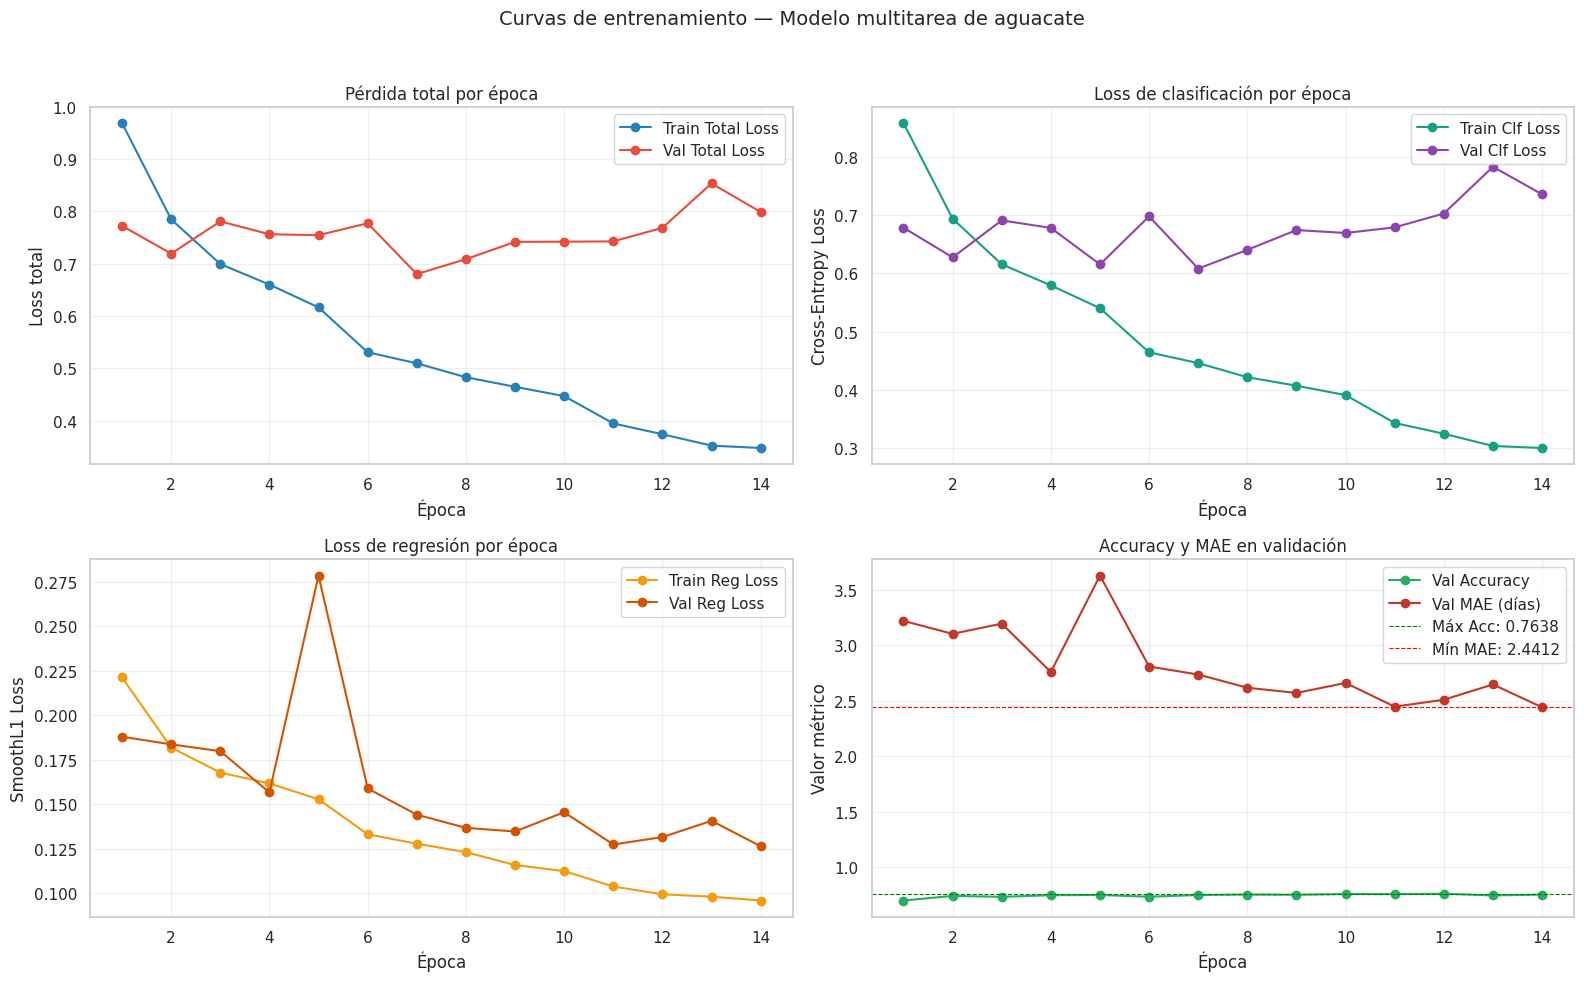

Val Accuracy final : 0.7561
Val Accuracy max   : 0.7638  (época 12)
Val MAE final      : 2.4412 días
Val MAE mínimo     : 2.4412 días  (época 14)


In [30]:
# ==============================================================================
# CELDA 10: CURVAS DE ENTRENAMIENTO (MULTITAREA)
# ==============================================================================

import matplotlib.pyplot as plt

# ── 10.0 Validaciones ──────────────────────────────────────────────────────────
claves_requeridas = [
    'train_loss_total', 'train_loss_clf', 'train_loss_reg',
    'val_loss_total', 'val_loss_clf', 'val_loss_reg',
    'val_acc', 'val_mae'
]

faltantes = [k for k in claves_requeridas if k not in historial]
if faltantes:
    raise ValueError(f'Faltan claves en historial: {faltantes}')

n_epocas_hist = len(historial['train_loss_total'])
if n_epocas_hist == 0:
    raise ValueError('El historial está vacío. Ejecuta primero la celda de entrenamiento.')

# usar la longitud real del historial por seguridad
epocas_eje = range(1, n_epocas_hist + 1)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
ax1, ax2, ax3, ax4 = axes.ravel()

# ── 10.1 Loss total ───────────────────────────────────────────────────────────
ax1.plot(epocas_eje, historial['train_loss_total'], label='Train Total Loss', marker='o', color='#2980b9')
ax1.plot(epocas_eje, historial['val_loss_total'],   label='Val Total Loss',   marker='o', color='#e74c3c')
ax1.set_title('Pérdida total por época', fontsize=12)
ax1.set_xlabel('Época')
ax1.set_ylabel('Loss total')
ax1.legend()
ax1.grid(True, alpha=0.3)

# ── 10.2 Loss clasificación ───────────────────────────────────────────────────
ax2.plot(epocas_eje, historial['train_loss_clf'], label='Train Clf Loss', marker='o', color='#16a085')
ax2.plot(epocas_eje, historial['val_loss_clf'],   label='Val Clf Loss',   marker='o', color='#8e44ad')
ax2.set_title('Loss de clasificación por época', fontsize=12)
ax2.set_xlabel('Época')
ax2.set_ylabel('Cross-Entropy Loss')
ax2.legend()
ax2.grid(True, alpha=0.3)

# ── 10.3 Loss regresión ───────────────────────────────────────────────────────
ax3.plot(epocas_eje, historial['train_loss_reg'], label='Train Reg Loss', marker='o', color='#f39c12')
ax3.plot(epocas_eje, historial['val_loss_reg'],   label='Val Reg Loss',   marker='o', color='#d35400')
ax3.set_title('Loss de regresión por época', fontsize=12)
ax3.set_xlabel('Época')
ax3.set_ylabel('SmoothL1 Loss')
ax3.legend()
ax3.grid(True, alpha=0.3)

# ── 10.4 Métricas de validación ───────────────────────────────────────────────
ax4.plot(epocas_eje, historial['val_acc'], label='Val Accuracy', marker='o', color='#27ae60')
ax4.plot(epocas_eje, historial['val_mae'], label='Val MAE (días)', marker='o', color='#c0392b')

best_acc = max(historial['val_acc'])
best_mae = min(historial['val_mae'])

ax4.axhline(best_acc, color='green', linestyle='--', linewidth=0.8,
            label=f'Máx Acc: {best_acc:.4f}')
ax4.axhline(best_mae, color='red', linestyle='--', linewidth=0.8,
            label=f'Mín MAE: {best_mae:.4f}')

ax4.set_title('Accuracy y MAE en validación', fontsize=12)
ax4.set_xlabel('Época')
ax4.set_ylabel('Valor métrico')
ax4.legend()
ax4.grid(True, alpha=0.3)

# ── 10.5 Layout final ─────────────────────────────────────────────────────────
plt.suptitle('Curvas de entrenamiento — Modelo multitarea de aguacate', fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# ── 10.6 Resumen numérico ─────────────────────────────────────────────────────
epoca_best_acc = historial['val_acc'].index(best_acc) + 1
epoca_best_mae = historial['val_mae'].index(best_mae) + 1

print(f'Val Accuracy final : {historial["val_acc"][-1]:.4f}')
print(f'Val Accuracy max   : {best_acc:.4f}  (época {epoca_best_acc})')
print(f'Val MAE final      : {historial["val_mae"][-1]:.4f} días')
print(f'Val MAE mínimo     : {best_mae:.4f} días  (época {epoca_best_mae})')

---
## CELDA 11 — Evaluación Final en Test Set

Test Accuracy (clasificación): 0.7892  (78.92%)

Reporte de clasificación por clase:
                                      precision    recall  f1-score   support

            Underripe (1) / Inmaduro       0.87      0.93      0.90       504
        Breaking (2) / En transición       0.77      0.64      0.70       322
     Ripe (First Stage) (3) / Maduro       0.70      0.80      0.75       378
Ripe (Second Stage) (4) / Muy maduro       0.74      0.72      0.73       516
               Overripe (5) / Pasado       0.86      0.81      0.83       424

                            accuracy                           0.79      2144
                           macro avg       0.79      0.78      0.78      2144
                        weighted avg       0.79      0.79      0.79      2144

MAE Test (regresión):  2.6021 días
RMSE Test (regresión): 3.3530 días


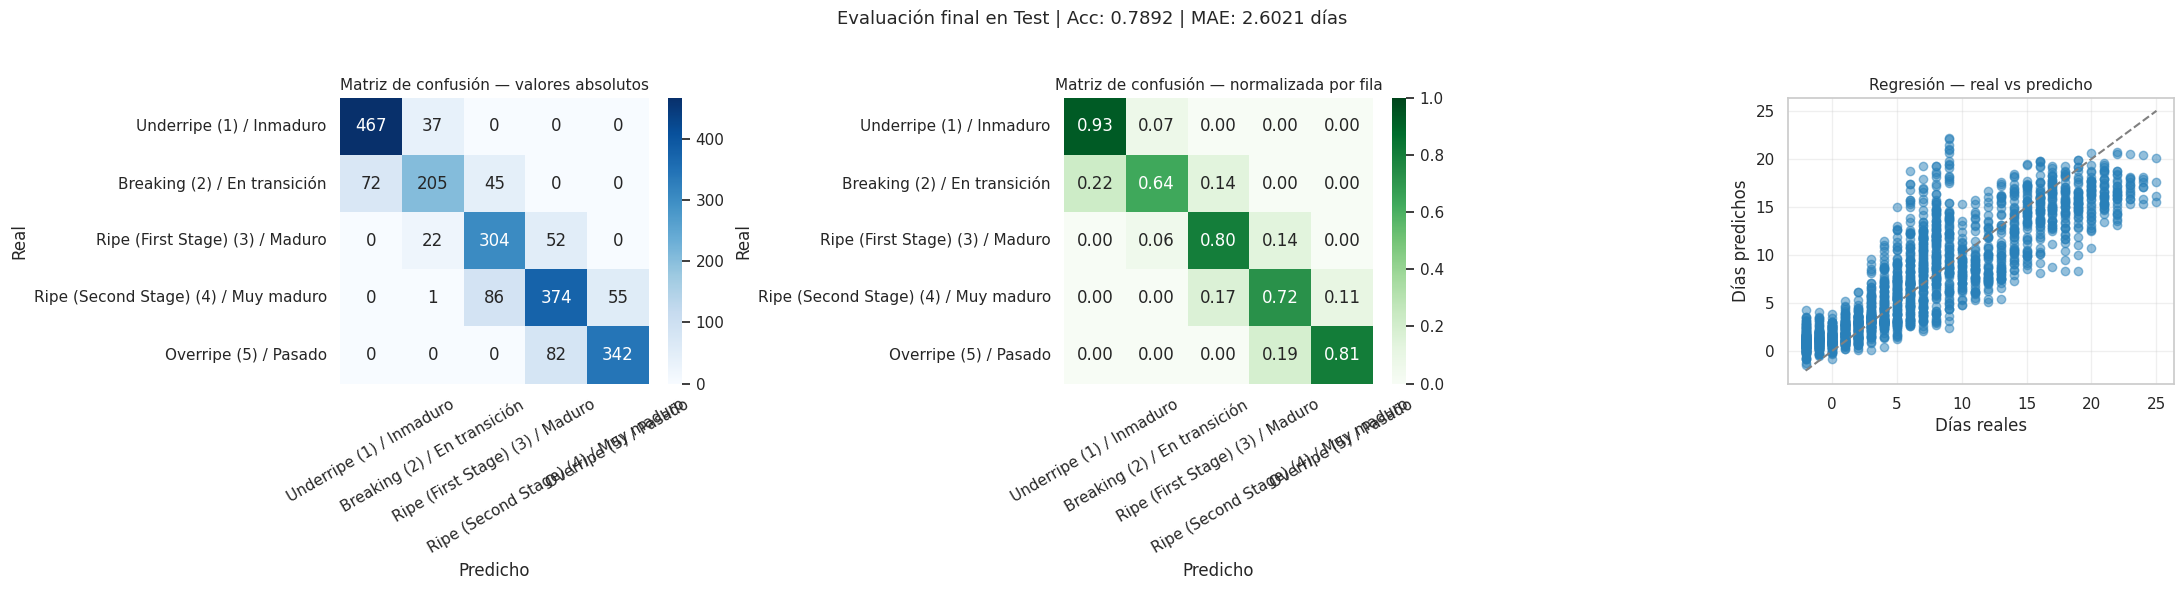


Ejemplos de regresión (primeros 12):
 Idx | Clase real | Clase pred |  Días reales |    Días pred
──────────────────────────────────────────────────────────────────────
   0 |          1 |          1 |         8.00 |        14.65
   1 |          1 |          1 |         8.00 |        13.57
   2 |          1 |          1 |         7.00 |        14.73
   3 |          1 |          1 |         7.00 |        11.72
   4 |          2 |          2 |         6.00 |         8.35
   5 |          2 |          2 |         6.00 |         7.01
   6 |          2 |          2 |         5.00 |         6.56
   7 |          2 |          3 |         5.00 |         6.47
   8 |          3 |          3 |         4.00 |         4.47
   9 |          3 |          3 |         4.00 |         5.21
  10 |          4 |          4 |         3.00 |         3.00
  11 |          4 |          3 |         3.00 |         3.77


In [31]:
# ==============================================================================
# CELDA 11: EVALUACIÓN FINAL EN TEST SET — CLASIFICACIÓN + REGRESIÓN
# ==============================================================================

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error, mean_squared_error

# ── 11.0 Validaciones ─────────────────────────────────────────────────────────
if 'REG_MEAN' not in globals() or 'REG_STD' not in globals():
    raise ValueError("REG_MEAN / REG_STD no están definidos. Ejecuta primero la celda 6.")

modelo.eval()

def unpack_batch_eval(batch, device):
    """
    Soporta:
      - (imgs, y_clf, y_reg)
      - (imgs, metas, y_clf, y_reg)  -> metas se ignora
    """
    if len(batch) == 3:
        imgs, y_clf, y_reg = batch
        metas = None
    elif len(batch) == 4:
        imgs, metas, y_clf, y_reg = batch
    else:
        raise ValueError(f"Batch inesperado con {len(batch)} elementos")

    imgs = imgs.to(device)
    y_clf = y_clf.to(device)
    y_reg = y_reg.to(device)

    if metas is not None:
        metas = metas.to(device)

    return imgs, metas, y_clf, y_reg

y_true_clf, y_pred_clf = [], []
y_true_reg, y_pred_reg = [], []

with torch.no_grad():
    for batch in test_loader:
        imgs, metas, y_clf, y_reg = unpack_batch_eval(batch, DEVICE)

        # modelo SOLO IMAGEN
        logits_clf, pred_reg = modelo(imgs)

        preds_clf = logits_clf.argmax(dim=1).cpu().numpy()

        # ✅ desnormalizar a días reales
        y_reg_real = (y_reg.cpu().numpy() * REG_STD) + REG_MEAN
        pred_reg_real = (pred_reg.cpu().numpy() * REG_STD) + REG_MEAN

        y_true_clf.extend(y_clf.cpu().numpy())
        y_pred_clf.extend(preds_clf)

        y_true_reg.extend(y_reg_real)
        y_pred_reg.extend(pred_reg_real)

# ── 11.1 Métricas de clasificación ────────────────────────────────────────────
y_true_clf = np.array(y_true_clf)
y_pred_clf = np.array(y_pred_clf)

acc_test = np.mean(y_true_clf == y_pred_clf)
print(f'Test Accuracy (clasificación): {acc_test:.4f}  ({acc_test*100:.2f}%)')
print()

nombres_clases = [NOMBRES_CLASE[i + 1] for i in range(N_CLASES)]
labels_ids = list(range(N_CLASES))

print('Reporte de clasificación por clase:')
print(
    classification_report(
        y_true_clf,
        y_pred_clf,
        labels=labels_ids,
        target_names=nombres_clases,
        zero_division=0
    )
)

cm = confusion_matrix(y_true_clf, y_pred_clf, labels=labels_ids)

cm_norm = np.divide(
    cm.astype(float),
    cm.sum(axis=1, keepdims=True),
    out=np.zeros_like(cm, dtype=float),
    where=cm.sum(axis=1, keepdims=True) != 0
)

# ── 11.2 Métricas de regresión ────────────────────────────────────────────────
y_true_reg = np.array(y_true_reg, dtype=float)
y_pred_reg = np.array(y_pred_reg, dtype=float)

mae_test = mean_absolute_error(y_true_reg, y_pred_reg)
rmse_test = np.sqrt(mean_squared_error(y_true_reg, y_pred_reg))

print(f'MAE Test (regresión):  {mae_test:.4f} días')
print(f'RMSE Test (regresión): {rmse_test:.4f} días')

# ── 11.3 Visualizaciones ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# Matriz de confusión absoluta
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=nombres_clases,
    yticklabels=nombres_clases,
    ax=axes[0]
)
axes[0].set_title('Matriz de confusión — valores absolutos', fontsize=11)
axes[0].set_ylabel('Real')
axes[0].set_xlabel('Predicho')
axes[0].tick_params(axis='x', rotation=30)

# Matriz de confusión normalizada
sns.heatmap(
    cm_norm, annot=True, fmt='.2f', cmap='Greens',
    xticklabels=nombres_clases,
    yticklabels=nombres_clases,
    ax=axes[1], vmin=0, vmax=1
)
axes[1].set_title('Matriz de confusión — normalizada por fila', fontsize=11)
axes[1].set_ylabel('Real')
axes[1].set_xlabel('Predicho')
axes[1].tick_params(axis='x', rotation=30)

# Regresión: real vs predicho
axes[2].scatter(y_true_reg, y_pred_reg, alpha=0.5, color='#2980b9')
min_val = min(y_true_reg.min(), y_pred_reg.min())
max_val = max(y_true_reg.max(), y_pred_reg.max())
axes[2].plot([min_val, max_val], [min_val, max_val], '--', color='gray')
axes[2].set_title('Regresión — real vs predicho', fontsize=11)
axes[2].set_xlabel('Días reales')
axes[2].set_ylabel('Días predichos')
axes[2].grid(True, alpha=0.3)

plt.suptitle(
    f'Evaluación final en Test | Acc: {acc_test:.4f} | MAE: {mae_test:.4f} días',
    fontsize=13
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# ── 11.4 Ejemplos concretos ───────────────────────────────────────────────────
print('\nEjemplos de regresión (primeros 12):')
print(f'{"Idx":>4} | {"Clase real":>10} | {"Clase pred":>10} | {"Días reales":>12} | {"Días pred":>12}')
print('─' * 70)

for i in range(min(12, len(y_true_reg))):
    real_clf = y_true_clf[i] + 1
    pred_clf = y_pred_clf[i] + 1
    real_reg_i = y_true_reg[i]
    pred_reg_i = y_pred_reg[i]
    print(f'{i:>4} | {real_clf:>10} | {pred_clf:>10} | {real_reg_i:>12.2f} | {pred_reg_i:>12.2f}')

---
## CELDA 12 — Análisis de Incertidumbre (MC Dropout)

 Idx | Real C | Pred C |     Conf |    Inc Clf |  Real días |  Pred días |    Inc Reg | Nivel
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   0 |      1 |      1 ✓ |   0.9698 |   0.000125 |       8.00 |      14.26 |     1.6518 | ALTA
   1 |      1 |      1 ✓ |   0.9395 |   0.000528 |       8.00 |      13.50 |     1.5738 | ALTA
   2 |      1 |      1 ✓ |   0.8963 |   0.001371 |       7.00 |      15.03 |     1.9719 | ALTA
   3 |      1 |      2 ✗ |   0.5147 |   0.005290 |       7.00 |      11.60 |     1.2519 | MEDIA
   4 |      2 |      2 ✓ |   0.9122 |   0.001522 |       6.00 |       8.78 |     1.3498 | ALTA
   5 |      2 |      2 ✓ |   0.9703 |   0.000251 |       6.00 |       6.78 |     1.2400 | ALTA
   6 |      2 |      2 ✓ |   0.8919 |   0.001543 |       5.00 |       6.77 |     1.2187 | ALTA
   7 |      2 |      3 ✗ |   0.7061 |   0.006495 |       5.00 |       6.46 |     0.9317 | ALTA
   8 |      3 |      3 ✓ |

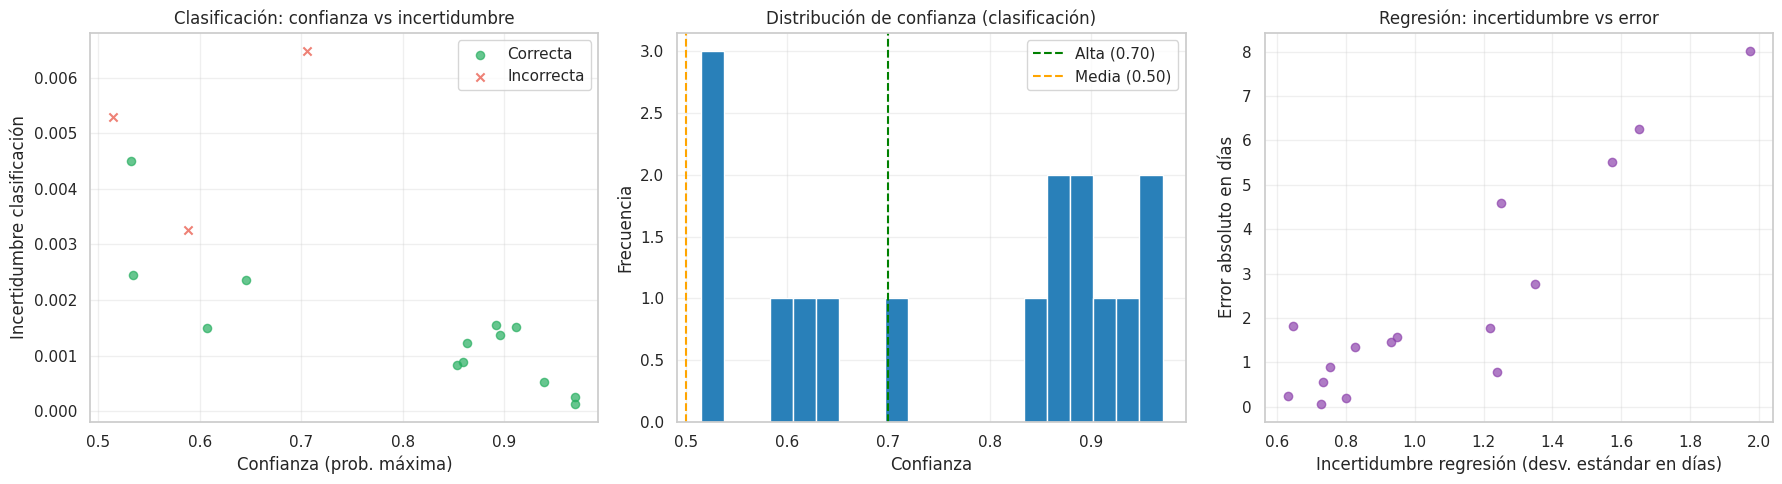


Confianza promedio batch (clasificación): 0.7679
% predicciones ALTA confianza (≥0.70): 62.5%
Incertidumbre promedio regresión: 1.0792 días
Error absoluto promedio batch: 2.3656 días


In [32]:
# ==============================================================================
# INCERTIDUMBRE — MC DROPOUT (CLF + REG, SOLO IMAGEN)
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt

if 'REG_MEAN' not in globals() or 'REG_STD' not in globals():
    raise ValueError("REG_MEAN y REG_STD no están definidos. Ejecuta primero la celda 6.")

batch_test = next(iter(test_loader))

if len(batch_test) == 3:
    imgs_test, y_clf_test, y_reg_test = batch_test
    metas_test = None
elif len(batch_test) == 4:
    imgs_test, metas_test, y_clf_test, y_reg_test = batch_test
else:
    raise ValueError(f"Formato inesperado en test_loader: {len(batch_test)} elementos")

imgs_test = imgs_test.to(DEVICE)

media_probs, var_probs, media_reg, var_reg = modelo.predict_con_incertidumbre(
    imgs_test, n_muestras=30
)

# ── Clasificación ──────────────────────────────────────────────────────────────
confianza = media_probs.max(dim=1).values.cpu().numpy()
preds_mc = media_probs.argmax(dim=1).cpu().numpy()
incertidumbre_clf = var_probs.mean(dim=1).cpu().numpy()

# ── Regresión (desnormalizada a días) ─────────────────────────────────────────
y_reg_test_real = (y_reg_test.numpy() * REG_STD) + REG_MEAN
pred_reg_media_real = (media_reg.cpu().numpy() * REG_STD) + REG_MEAN

# var_real = var_norm * std^2
var_reg_real = var_reg.cpu().numpy() * (REG_STD ** 2)

# ✅ más interpretable: desviación estándar en días
incertidumbre_reg_dias = np.sqrt(np.maximum(var_reg_real, 0.0))

def nivel_certeza(conf: float) -> str:
    if conf >= 0.70:
        return 'ALTA'
    if conf >= 0.50:
        return 'MEDIA'
    return 'BAJA'

print(f'{"Idx":>4} | {"Real C":>6} | {"Pred C":>6} | {"Conf":>8} | {"Inc Clf":>10} | {"Real días":>10} | {"Pred días":>10} | {"Inc Reg":>10} | Nivel')
print('─' * 118)

for i in range(min(12, len(preds_mc))):
    real_c = y_clf_test[i].item() + 1
    pred_c = preds_mc[i] + 1
    conf = confianza[i]
    inc_c = incertidumbre_clf[i]
    real_d = y_reg_test_real[i]
    pred_d = pred_reg_media_real[i]
    inc_d = incertidumbre_reg_dias[i]
    nivel = nivel_certeza(conf)
    marca = '✓' if real_c == pred_c else '✗'

    print(f'{i:>4} | {real_c:>6} | {pred_c:>6} {marca} | {conf:>8.4f} | {inc_c:>10.6f} | '
          f'{real_d:>10.2f} | {pred_d:>10.2f} | {inc_d:>10.4f} | {nivel}')

# ── Visualizaciones ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Confianza vs incertidumbre clasificación
correctas_mc = (preds_mc == y_clf_test.numpy())

axes[0].scatter(
    confianza[correctas_mc], incertidumbre_clf[correctas_mc],
    c='#27ae60', alpha=0.7, label='Correcta', s=35
)
axes[0].scatter(
    confianza[~correctas_mc], incertidumbre_clf[~correctas_mc],
    c='#e74c3c', alpha=0.7, label='Incorrecta', s=35, marker='x'
)
axes[0].set_xlabel('Confianza (prob. máxima)')
axes[0].set_ylabel('Incertidumbre clasificación')
axes[0].set_title('Clasificación: confianza vs incertidumbre')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2) Distribución de confianza
axes[1].hist(confianza, bins=20, color='#2980b9', edgecolor='white')
axes[1].axvline(0.70, color='green', linestyle='--', label='Alta (0.70)')
axes[1].axvline(0.50, color='orange', linestyle='--', label='Media (0.50)')
axes[1].set_title('Distribución de confianza (clasificación)')
axes[1].set_xlabel('Confianza')
axes[1].set_ylabel('Frecuencia')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# 3) Incertidumbre regresión vs error absoluto
abs_error_reg = np.abs(pred_reg_media_real - y_reg_test_real)

axes[2].scatter(incertidumbre_reg_dias, abs_error_reg, alpha=0.7, color='#8e44ad')
axes[2].set_xlabel('Incertidumbre regresión (desv. estándar en días)')
axes[2].set_ylabel('Error absoluto en días')
axes[2].set_title('Regresión: incertidumbre vs error')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'\nConfianza promedio batch (clasificación): {confianza.mean():.4f}')
print(f'% predicciones ALTA confianza (≥0.70): {100*(confianza >= 0.70).mean():.1f}%')
print(f'Incertidumbre promedio regresión: {incertidumbre_reg_dias.mean():.4f} días')
print(f'Error absoluto promedio batch: {abs_error_reg.mean():.4f} días')



---
## CELDA 13 — Guardar Modelo Entrenado

In [33]:
# ==============================================================================
# CELDA 13: GUARDAR EL MODELO ENTRENADO (MULTITAREA, SOLO IMAGEN)
# ==============================================================================

from pathlib import Path
import torch

MODELS_DIR = PROYECTO_DIR / 'models'
MODELS_DIR.mkdir(exist_ok=True)

checkpoint = {
    'model_state_dict': modelo.state_dict(),
    'model_class': 'ResNet50AguacateSoloImagen',
    'task_type': 'multitask_image_only',
    'n_clases': N_CLASES,
    'dropout_p': 0.4,

    # ✅ target real
    'target_reg': 'dias_hasta_podrido',
    'target_reg_internal': 'y_reg_norm',

    # ✅ normalización de regresión
    'reg_mean': REG_MEAN,
    'reg_std': REG_STD,

    # entrenamiento
    'epocas': EPOCAS,
    'val_loss_min': mejor_val_loss,
    'val_acc_final': historial['val_acc'][-1],
    'val_acc_max': max(historial['val_acc']),
    'val_mae_final': historial['val_mae'][-1],
    'val_mae_min': min(historial['val_mae']),

    # test
    'test_acc': acc_test,
    'test_mae': mae_test,
    'test_rmse': rmse_test,

    # historial completo
    'historial': historial,

    # clases
    'nombres_clase': NOMBRES_CLASE,

    # control
    'seed': SEED,
}

ruta_modelo = MODELS_DIR / 'modelo_multitarea_aguacate_solo_imagen.pth'
torch.save(checkpoint, ruta_modelo)

print(f'Modelo guardado en : {ruta_modelo}')
print(f'Val Accuracy final : {historial["val_acc"][-1]:.4f}')
print(f'Val Accuracy máx   : {max(historial["val_acc"]):.4f}')
print(f'Val MAE mínimo     : {min(historial["val_mae"]):.4f} días')
print(f'Test Accuracy      : {acc_test:.4f}')
print(f'Test MAE           : {mae_test:.4f} días')
print(f'Test RMSE          : {rmse_test:.4f} días')

# ── Opcional: copiar a Google Drive si estamos en Colab ──────────────────────
if IN_COLAB:
    import shutil
    dst = Path('/content/drive/MyDrive/proyecto_si/modelo_multitarea_aguacate_solo_imagen.pth')
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(ruta_modelo, dst)
    print(f'Modelo copiado a Drive: {dst}')

Modelo guardado en : /content/Proyecto_SI_2026I/models/modelo_multitarea_aguacate_solo_imagen.pth
Val Accuracy final : 0.7561
Val Accuracy máx   : 0.7638
Val MAE mínimo     : 2.4412 días
Test Accuracy      : 0.7892
Test MAE           : 2.6021 días
Test RMSE          : 3.3530 días
Modelo copiado a Drive: /content/drive/MyDrive/proyecto_si/modelo_multitarea_aguacate_solo_imagen.pth


---
## CELDA 14 — Resumen Ejecutivo y Próximos Pasos

In [34]:
# ==============================================================================
# CELDA 14: RESUMEN EJECUTIVO
# ==============================================================================

print('=' * 80)
print('  RESUMEN DEL MODELO — Aguacate Hass (Clasificación + Estimación de Tiempo)')
print('=' * 80)

params_train = sum(p.numel() for p in modelo.parameters() if p.requires_grad)

print(f"""
DATASET
  Total imágenes analizadas : {len(df_valid):,}
  Muestras únicas           : {df_valid['grupo_muestra'].nunique():,}
  Grupos de almacenamiento  : T10 (10°C), T20 (20°C), Tam (ambiente)
  Clases (Ripening Index)   : 5 (1=Underripe → 5=Overripe)
  Split anti-leakage        : por muestra biológica (no por imagen)
  Train / Val / Test        : {len(df_train):,} / {len(df_val):,} / {len(df_test):,}

TARGETS DEL MODELO
  Clasificación             : estado de maduración (5 clases)
  Regresión                 : días hasta estado podrido
  Variable interna de train : y_reg_norm (normalizada)
  Interpretación práctica   : tiempo restante estimado hasta deterioro completo

MODELO
  Arquitectura              : ResNet50 + MC Dropout
  Tipo                      : Solo imagen + Multitarea
  Backbone visual           : ResNet50 (ImageNet V2), layer4 fine-tuned
  Tronco compartido         : FC(2048→512→128)
  Cabeza clasificación      : 128→{N_CLASES}
  Cabeza regresión          : 128→1 (sin activación final)
  Parámetros entrenables    : {params_train:,}

ENTRENAMIENTO
  Optimizador               : AdamW (lr=1e-3, wd=1e-4)
  Scheduler                 : StepLR (step=5, gamma=0.5)
  Épocas                    : {EPOCAS}
  Batch size                : {BATCH_SIZE}
  Device                    : {DEVICE}
  Lambda regresión          : {LAMBDA_REG}

NORMALIZACIÓN DE REGRESIÓN
  REG_MEAN                  : {REG_MEAN:.4f}
  REG_STD                   : {REG_STD:.4f}

RESULTADOS — VALIDACIÓN
  Val Accuracy (mejor)      : {max(historial['val_acc']):.4f} ({max(historial['val_acc'])*100:.2f}%)
  Val MAE (mínimo)          : {min(historial['val_mae']):.4f} días
  Val Loss mínima           : {mejor_val_loss:.4f}

RESULTADOS — TEST
  Test Accuracy             : {acc_test:.4f} ({acc_test*100:.2f}%)
  Test MAE                  : {mae_test:.4f} días
  Test RMSE                 : {rmse_test:.4f} días
""")

print('INTERPRETACIÓN DEL MODELO')
print('  • El modelo clasifica el estado del aguacate en 5 fases reales del dataset.')
print('  • Además estima cuántos días faltan para llegar al estado podrido.')
print('  • El modelo final requiere únicamente una imagen en inferencia.')
print('  • MC Dropout permite estimar confianza e incertidumbre en predicción.')
print()

print('PRÓXIMOS PASOS')
print('  1. Comparar esta versión solo imagen contra una versión multimodal como benchmark.')
print('  2. Ajustar LAMBDA_REG para balancear mejor clasificación y regresión.')
print('  3. Descongelar layer3 + layer4 y re-entrenar con lr=1e-4 (fine-tuning profundo).')
print('  4. Probar oversampling o WeightedRandomSampler si hay clases minoritarias.')
print('  5. Evaluar calibración de incertidumbre y MAE por clase.')
print('  6. Exportar a TorchScript / ONNX para despliegue.')
print('  7. Integrar FastAPI para retornar estado, días restantes y nivel de confianza.')

  RESUMEN DEL MODELO — Aguacate Hass (Clasificación + Estimación de Tiempo)

DATASET
  Total imágenes analizadas : 13,604
  Muestras únicas           : 410
  Grupos de almacenamiento  : T10 (10°C), T20 (20°C), Tam (ambiente)
  Clases (Ripening Index)   : 5 (1=Underripe → 5=Overripe)
  Split anti-leakage        : por muestra biológica (no por imagen)
  Train / Val / Test        : 9,246 / 2,214 / 2,144

TARGETS DEL MODELO
  Clasificación             : estado de maduración (5 clases)
  Regresión                 : días hasta estado podrido
  Variable interna de train : y_reg_norm (normalizada)
  Interpretación práctica   : tiempo restante estimado hasta deterioro completo

MODELO
  Arquitectura              : ResNet50 + MC Dropout
  Tipo                      : Solo imagen + Multitarea
  Backbone visual           : ResNet50 (ImageNet V2), layer4 fine-tuned
  Tronco compartido         : FC(2048→512→128)
  Cabeza clasificación      : 128→5
  Cabeza regresión          : 128→1 (sin activación f